# DUET — Week 6: Scheduling Cost Models and Bubble Analysis

This notebook is the cleaned, reproducible Week 6 analysis notebook.

## M0 — Freeze and Audit the Week 5 Baseline

Completed in the Week 5 notebook.

Verified:
- The historical scheduler orders prompts by descending estimated cost.
- Each prompt is assigned to the worker with the smallest estimated additive load.
- Worker true costs are accumulated additively.
- Makespan is the maximum true worker load.
- Therefore the Week 5 simulator implements a sequential-sum cost assumption.

Week 6 replaces that assumption with explicit `sum`, `max`, and `wave(C)` execution models.

**Reproducibility rule:** run this notebook top-to-bottom from a fresh kernel. All Week 6 results use explicit chronological ordering and no current-batch leakage.

# M1 — Reconstruct True Per-Prompt Generation Cost

Goal: reload the independent 16-batch trace, recover the 2,048 prompt occurrences, preserve all five rollout lengths per occurrence, and construct the corrected `sum_5` and `max_5` costs.

In [1]:
# M1.1 — Imports, fixed paths, and chronological trace loading

from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from transformers import AutoTokenizer

TRACE_DIR = Path(
    r"C:\Users\waqar\OneDrive\Desktop\Fellowship\trace_rollout_training_steps"
)

WEEK6_DIR = Path(
    r"C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6"
)

TOKENIZER_NAME = "Qwen/Qwen2.5-Math-1.5B"

trace_files = sorted(
    TRACE_DIR.glob("*.jsonl"),
    key=lambda p: int(p.stem),
)

assert len(trace_files) == 16, (
    f"Expected 16 JSONL files, found {len(trace_files)}"
)

parts = []

for path in trace_files:
    df = pd.read_json(path, lines=True)
    df["batch_step"] = int(path.stem)
    df["source_file"] = path.name
    parts.append(df)

trace_rollouts = pd.concat(
    parts,
    ignore_index=True,
)

assert len(trace_rollouts) == 10_240
assert trace_rollouts["batch_step"].nunique() == 16
assert (
    trace_rollouts["batch_step"]
    .value_counts()
    .sort_index()
    .eq(640)
    .all()
)

print("Files:", [p.name for p in trace_files])
print("Trace shape:", trace_rollouts.shape)
print("Rows per batch: 640")
print("✅ Raw trace loaded chronologically.")

c:\Users\waqar\OneDrive\Desktop\Fellowship\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files: ['1.jsonl', '2.jsonl', '3.jsonl', '4.jsonl', '5.jsonl', '6.jsonl', '7.jsonl', '8.jsonl', '9.jsonl', '10.jsonl', '11.jsonl', '12.jsonl', '13.jsonl', '14.jsonl', '15.jsonl', '16.jsonl']
Trace shape: (10240, 8)
Rows per batch: 640
✅ Raw trace loaded chronologically.


In [2]:
# M1.2 — Recover prompt-occurrence identity and validate 5-rollout groups

trace_rollouts["occurrence_id"] = (
    trace_rollouts["uid"]
    .astype(str)
    .str.replace(r"_\d+_\d+$", "", regex=True)
)

trace_rollouts["rollout_idx"] = (
    trace_rollouts["uid"]
    .astype(str)
    .str.extract(r"_(\d+)_\d+$")[0]
    .astype(int)
)

occurrence_counts = (
    trace_rollouts
    .groupby(["batch_step", "occurrence_id"])
    .size()
    .rename("n_rollouts")
    .reset_index()
)

assert len(occurrence_counts) == 2_048
assert occurrence_counts["n_rollouts"].eq(5).all()
assert (
    occurrence_counts
    .groupby("batch_step")
    .size()
    .eq(128)
    .all()
)

expected_rollout_idx = {0, 1, 2, 3, 4}
assert set(trace_rollouts["rollout_idx"].unique()) == expected_rollout_idx

print("Prompt occurrences:", len(occurrence_counts))
print("Occurrences per batch: 128")
print("Rollouts per occurrence: 5")
print("✅ Prompt-occurrence grouping validated.")

Prompt occurrences: 2048
Occurrences per batch: 128
Rollouts per occurrence: 5
✅ Prompt-occurrence grouping validated.


In [3]:
# M1.3 — Re-tokenize outputs and build the true five-rollout cost table

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

outputs = trace_rollouts["output"].astype(str).tolist()
resp_lengths = []

TOKENIZE_BATCH_SIZE = 256

for start in range(0, len(outputs), TOKENIZE_BATCH_SIZE):
    batch_outputs = outputs[start:start + TOKENIZE_BATCH_SIZE]

    encoded = tokenizer(
        batch_outputs,
        add_special_tokens=False,
        truncation=False,
        padding=False,
    )

    resp_lengths.extend(
        len(ids)
        for ids in encoded["input_ids"]
    )

trace_rollouts["resp_len"] = np.asarray(
    resp_lengths,
    dtype=int,
)

assert len(trace_rollouts) == len(resp_lengths)
assert trace_rollouts["resp_len"].notna().all()

trace_rollouts = (
    trace_rollouts
    .sort_values(
        ["batch_step", "occurrence_id", "rollout_idx"],
        kind="stable",
    )
    .reset_index(drop=True)
)

prompt_costs = (
    trace_rollouts
    .groupby(
        ["batch_step", "occurrence_id"],
        sort=False,
        as_index=False,
    )
    .agg(
        input=("input", "first"),
        n_rollouts=("resp_len", "size"),
        rollout_lengths=(
            "resp_len",
            lambda x: tuple(int(v) for v in x),
        ),
        mean_5=("resp_len", "mean"),
        sum_5=("resp_len", "sum"),
        max_5=("resp_len", "max"),
        pass_rate=("score", "mean"),
    )
)

assert len(prompt_costs) == 2_048
assert prompt_costs["n_rollouts"].eq(5).all()
assert prompt_costs["rollout_lengths"].apply(len).eq(5).all()
assert np.allclose(
    prompt_costs["sum_5"],
    prompt_costs["mean_5"] * 5,
)

print(
    prompt_costs[
        ["mean_5", "sum_5", "max_5"]
    ]
    .describe()
)

print("\nExpected historical checks:")
print("mean(mean_5) ≈ 815.92168")
print("max(max_5)   = 5563")
print("\nObserved:")
print("mean(mean_5) =", prompt_costs["mean_5"].mean())
print("max(max_5)   =", prompt_costs["max_5"].max())
print("✅ Correct five-rollout costs constructed.")

            mean_5         sum_5        max_5
count  2048.000000   2048.000000  2048.000000
mean    815.921680   4079.608398  1945.719727
std     422.870642   2114.353211  1057.508899
min     116.800000    584.000000   200.000000
25%     465.650000   2328.250000   864.750000
50%     777.700000   3888.500000  2070.500000
75%    1070.950000   5354.750000  3072.000000
max    2685.800000  13429.000000  5563.000000

Expected historical checks:
mean(mean_5) ≈ 815.92168
max(max_5)   = 5563

Observed:
mean(mean_5) = 815.9216796875
max(max_5)   = 5563
✅ Correct five-rollout costs constructed.


In [4]:
# M1.4 — Final integrity checks and freeze the Week 6 cost artifact

assert prompt_costs["sum_5"].ge(prompt_costs["max_5"]).all()
assert prompt_costs["max_5"].ge(prompt_costs["mean_5"]).all()
assert prompt_costs[["mean_5", "sum_5", "max_5"]].gt(0).all().all()

for row in prompt_costs.itertuples():
    lengths = np.asarray(row.rollout_lengths, dtype=float)

    assert len(lengths) == 5
    assert np.isclose(lengths.mean(), row.mean_5)
    assert np.isclose(lengths.sum(), row.sum_5)
    assert np.isclose(lengths.max(), row.max_5)

cost_artifact = prompt_costs.copy()

for i in range(5):
    cost_artifact[f"rollout_len_{i}"] = (
        cost_artifact["rollout_lengths"]
        .apply(lambda x: int(x[i]))
    )

cost_artifact = cost_artifact.drop(
    columns=["rollout_lengths"]
)

OUTPUT_PATH = WEEK6_DIR / "week6_prompt_costs.csv"

cost_artifact.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("Prompt occurrences:", len(cost_artifact))
print("Batches:", cost_artifact["batch_step"].nunique())
print("Mean old Week 5 cost:", cost_artifact["mean_5"].mean())
print("Mean corrected SUM cost:", cost_artifact["sum_5"].mean())
print("Mean corrected MAX cost:", cost_artifact["max_5"].mean())
print("Saved:", OUTPUT_PATH)
print("✅ M1 COMPLETE")

Prompt occurrences: 2048
Batches: 16
Mean old Week 5 cost: 815.9216796875
Mean corrected SUM cost: 4079.6083984375
Mean corrected MAX cost: 1945.7197265625
Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_prompt_costs.csv
✅ M1 COMPLETE


# M2 — Implement Sum, Max, and Wave Execution Models

The simulator below is the **single canonical implementation** used by all later milestones.

- `sum`: worker time is the sum of all assigned sequence lengths.
- `max`: worker time is the longest assigned sequence.
- `wave(C)`: the worker processes consecutive waves of at most `C` sequences, and each wave costs the longest sequence in that wave.

For `sum`, assignment uses mean-scale prompt costs so multiplying every five-rollout prompt by the common factor 5 cannot introduce floating-point tie changes.

In [11]:
# M2.1 — Final canonical model-aware simulator

VALID_COST_MODELS = {
    "sum",
    "max",
    "wave",
}


def worker_time(
    sequence_lengths,
    cost_model="sum",
    concurrency=None,
):
    lengths = np.asarray(
        sequence_lengths,
        dtype=float,
    )

    if cost_model not in VALID_COST_MODELS:
        raise ValueError(
            f"Unknown cost_model={cost_model!r}. "
            f"Choose from {sorted(VALID_COST_MODELS)}."
        )

    if lengths.size == 0:
        return 0.0

    if np.any(lengths < 0):
        raise ValueError(
            "Sequence lengths must be non-negative."
        )

    # --------------------------------------------------------
    # SUM
    # --------------------------------------------------------

    if cost_model == "sum":
        return float(lengths.sum())

    # --------------------------------------------------------
    # MAX
    # --------------------------------------------------------

    if cost_model == "max":
        return float(lengths.max())

    # --------------------------------------------------------
    # WAVE
    # --------------------------------------------------------

    if concurrency is None:
        raise ValueError(
            "concurrency must be provided for wave mode."
        )

    if (
        not isinstance(concurrency, (int, np.integer))
        or concurrency < 1
    ):
        raise ValueError(
            "concurrency must be a positive integer."
        )

    total = 0.0

    for start in range(
        0,
        len(lengths),
        concurrency,
    ):
        wave = lengths[
            start:start + concurrency
        ]

        total += float(wave.max())

    return total


def _prepare_estimated_matrix(
    estimated_lengths,
    n_prompts,
    n_rollouts,
):
    """
    Convert estimated lengths into an
    (n_prompts, n_rollouts) matrix.

    1D input:
        one predicted length per prompt,
        repeated across its rollouts.

    2D input:
        explicit predicted rollout lengths.
    """

    estimated = np.asarray(
        estimated_lengths,
        dtype=float,
    )

    if estimated.ndim == 1:

        if len(estimated) != n_prompts:
            raise ValueError(
                "1D estimated_lengths must contain "
                "one value per prompt."
            )

        return np.repeat(
            estimated[:, None],
            n_rollouts,
            axis=1,
        )

    if estimated.ndim == 2:

        expected_shape = (
            n_prompts,
            n_rollouts,
        )

        if estimated.shape != expected_shape:
            raise ValueError(
                f"Expected estimated matrix shape "
                f"{expected_shape}, got {estimated.shape}."
            )

        return estimated.copy()

    raise ValueError(
        "estimated_lengths must be 1D or 2D."
    )


def simulate_assignment_v2(
    true_rollout_lengths,
    estimated_lengths,
    n_workers=2,
    cost_model="sum",
    concurrency=None,
):
    """
    Canonical Week 6 assignment simulator.

    Each row of true_rollout_lengths corresponds to one prompt
    and contains the lengths of its five generated rollouts.

    Assignment:
    - process prompts longest-estimated-first
    - greedily assign each prompt to the worker whose estimated
      completion time would be smallest after receiving it
    - evaluate final makespan using TRUE rollout lengths
    """

    # --------------------------------------------------------
    # Basic validation
    # --------------------------------------------------------

    if cost_model not in VALID_COST_MODELS:
        raise ValueError(
            f"Unknown cost_model={cost_model!r}."
        )

    if n_workers < 1:
        raise ValueError(
            "n_workers must be >= 1."
        )

    true_matrix = np.asarray(
        true_rollout_lengths,
        dtype=float,
    )

    if true_matrix.ndim != 2:
        raise ValueError(
            "true_rollout_lengths must be 2D."
        )

    if np.any(true_matrix < 0):
        raise ValueError(
            "True rollout lengths must be non-negative."
        )

    n_prompts, n_rollouts = true_matrix.shape

    estimated_raw = np.asarray(
        estimated_lengths,
        dtype=float,
    )

    estimated_matrix = _prepare_estimated_matrix(
        estimated_lengths,
        n_prompts=n_prompts,
        n_rollouts=n_rollouts,
    )

    # --------------------------------------------------------
    # Exact limiting identity:
    #
    # WAVE with C=1 is mathematically identical to SUM.
    #
    # Delegate to the SUM branch so multiplying all prompt
    # costs by the common rollout-count factor cannot create
    # floating-point tie differences in assignment.
    # --------------------------------------------------------

    if (
        cost_model == "wave"
        and concurrency == 1
    ):
        result = simulate_assignment_v2(
            true_rollout_lengths=true_matrix,
            estimated_lengths=estimated_lengths,
            n_workers=n_workers,
            cost_model="sum",
            concurrency=None,
        )

        result["cost_model"] = "wave"
        result["concurrency"] = 1

        return result

    # --------------------------------------------------------
    # SUM
    # --------------------------------------------------------

    if cost_model == "sum":

        # All prompts contain the same number of rollouts.
        #
        # Therefore:
        #
        #     sum_cost = n_rollouts * mean_cost
        #
        # Multiplying every estimated prompt cost by the same
        # positive constant cannot change the theoretical LPT
        # assignment.
        #
        # Use mean-scale costs here to avoid floating-point
        # tie changes caused only by the common factor.

        if estimated_raw.ndim == 1:

            assignment_costs = (
                estimated_raw.copy()
            )

        else:

            assignment_costs = (
                estimated_matrix.mean(axis=1)
            )

        order = np.argsort(
            -assignment_costs,
            kind="stable",
        )

        assignment_loads = np.zeros(
            n_workers,
            dtype=float,
        )

        assignments = np.empty(
            n_prompts,
            dtype=int,
        )

        true_worker_sequences = [
            []
            for _ in range(n_workers)
        ]

        estimated_worker_sequences = [
            []
            for _ in range(n_workers)
        ]

        for prompt_idx in order:

            worker = int(
                np.argmin(
                    assignment_loads
                )
            )

            assignments[
                prompt_idx
            ] = worker

            assignment_loads[
                worker
            ] += assignment_costs[
                prompt_idx
            ]

            true_worker_sequences[
                worker
            ].extend(
                true_matrix[
                    prompt_idx
                ].tolist()
            )

            estimated_worker_sequences[
                worker
            ].extend(
                estimated_matrix[
                    prompt_idx
                ].tolist()
            )

        true_worker_times = np.array(
            [
                float(
                    np.sum(seq)
                )
                for seq
                in true_worker_sequences
            ],
            dtype=float,
        )

        estimated_worker_times = np.array(
            [
                float(
                    np.sum(seq)
                )
                for seq
                in estimated_worker_sequences
            ],
            dtype=float,
        )

        return {
            "cost_model":
                "sum",

            "concurrency":
                None,

            "makespan":
                float(
                    true_worker_times.max()
                ),

            "true_worker_times":
                true_worker_times,

            "estimated_worker_times":
                estimated_worker_times,

            "assignments":
                assignments,

            "order":
                order,

            "estimated_prompt_costs":
                assignment_costs
                * n_rollouts,

            "true_worker_sequences":
                true_worker_sequences,

            "estimated_worker_sequences":
                estimated_worker_sequences,
        }

    # --------------------------------------------------------
    # MAX / WAVE
    # --------------------------------------------------------

    estimated_prompt_costs = np.array(
        [
            worker_time(
                estimated_matrix[i],
                cost_model=cost_model,
                concurrency=concurrency,
            )
            for i in range(
                n_prompts
            )
        ],
        dtype=float,
    )

    order = np.argsort(
        -estimated_prompt_costs,
        kind="stable",
    )

    assignments = np.empty(
        n_prompts,
        dtype=int,
    )

    true_worker_sequences = [
        []
        for _ in range(
            n_workers
        )
    ]

    estimated_worker_sequences = [
        []
        for _ in range(
            n_workers
        )
    ]

    for prompt_idx in order:

        candidate_times = np.empty(
            n_workers,
            dtype=float,
        )

        prompt_vector = (
            estimated_matrix[
                prompt_idx
            ]
            .tolist()
        )

        for worker in range(
            n_workers
        ):

            candidate_sequences = (
                estimated_worker_sequences[
                    worker
                ]
                + prompt_vector
            )

            candidate_times[
                worker
            ] = worker_time(
                candidate_sequences,
                cost_model=cost_model,
                concurrency=concurrency,
            )

        worker = int(
            np.argmin(
                candidate_times
            )
        )

        assignments[
            prompt_idx
        ] = worker

        estimated_worker_sequences[
            worker
        ].extend(
            prompt_vector
        )

        true_worker_sequences[
            worker
        ].extend(
            true_matrix[
                prompt_idx
            ].tolist()
        )

    estimated_worker_times = np.array(
        [
            worker_time(
                seq,
                cost_model=cost_model,
                concurrency=concurrency,
            )
            for seq
            in estimated_worker_sequences
        ],
        dtype=float,
    )

    true_worker_times = np.array(
        [
            worker_time(
                seq,
                cost_model=cost_model,
                concurrency=concurrency,
            )
            for seq
            in true_worker_sequences
        ],
        dtype=float,
    )

    return {
        "cost_model":
            cost_model,

        "concurrency":
            concurrency,

        "makespan":
            float(
                true_worker_times.max()
            ),

        "true_worker_times":
            true_worker_times,

        "estimated_worker_times":
            estimated_worker_times,

        "assignments":
            assignments,

        "order":
            order,

        "estimated_prompt_costs":
            estimated_prompt_costs,

        "true_worker_sequences":
            true_worker_sequences,

        "estimated_worker_sequences":
            estimated_worker_sequences,
    }


print(
    "✅ Final M2 simulator defined."
)

print(
    "Available models:",
    sorted(
        VALID_COST_MODELS
    ),
)

✅ Final M2 simulator defined.
Available models: ['max', 'sum', 'wave']


# M3 — Validate the Cost Models on Hand-Checkable Synthetic Cases

These tests run **after the final simulator definition**. They verify arithmetic, assignment behavior, and the limiting identities:

- `wave(C=1) = sum`
- sufficiently large `C` makes `wave = max`

In [12]:
# M3.1 — Synthetic validation

print("=" * 80)
print("TEST 1 — ONE WORKER-TIME VECTOR")
print("=" * 80)

lengths = [10, 20, 30, 40, 50]

assert worker_time(lengths, "sum") == 150
assert worker_time(lengths, "max") == 50
assert worker_time(lengths, "wave", concurrency=1) == 150
assert worker_time(lengths, "wave", concurrency=2) == 110
assert worker_time(lengths, "wave", concurrency=5) == 50
assert worker_time(lengths, "wave", concurrency=10) == 50

print("✅ Worker-time arithmetic passed.")

toy_true = np.array(
    [
        [10, 10, 10, 10, 10],
        [5, 5, 5, 5, 5],
        [4, 4, 4, 4, 4],
    ],
    dtype=float,
)

toy_est = toy_true.copy()

result_sum = simulate_assignment_v2(
    true_rollout_lengths=toy_true,
    estimated_lengths=toy_est,
    n_workers=2,
    cost_model="sum",
)

assert np.array_equal(
    result_sum["assignments"],
    np.array([0, 1, 1]),
)
assert np.allclose(
    result_sum["true_worker_times"],
    [50, 45],
)
assert result_sum["makespan"] == 50

result_max = simulate_assignment_v2(
    true_rollout_lengths=toy_true,
    estimated_lengths=toy_est,
    n_workers=2,
    cost_model="max",
)

assert np.array_equal(
    result_max["assignments"],
    np.array([0, 1, 1]),
)
assert np.allclose(
    result_max["true_worker_times"],
    [10, 5],
)
assert result_max["makespan"] == 10

result_wave5 = simulate_assignment_v2(
    true_rollout_lengths=toy_true,
    estimated_lengths=toy_est,
    n_workers=2,
    cost_model="wave",
    concurrency=5,
)

assert np.array_equal(
    result_wave5["assignments"],
    np.array([0, 1, 1]),
)
assert np.allclose(
    result_wave5["true_worker_times"],
    [10, 9],
)
assert result_wave5["makespan"] == 10

wave1 = simulate_assignment_v2(
    true_rollout_lengths=toy_true,
    estimated_lengths=toy_est,
    n_workers=2,
    cost_model="wave",
    concurrency=1,
)

assert np.array_equal(
    wave1["assignments"],
    result_sum["assignments"],
)
assert np.allclose(
    wave1["true_worker_times"],
    result_sum["true_worker_times"],
)
assert np.isclose(
    wave1["makespan"],
    result_sum["makespan"],
)

wave_huge = simulate_assignment_v2(
    true_rollout_lengths=toy_true,
    estimated_lengths=toy_est,
    n_workers=2,
    cost_model="wave",
    concurrency=100,
)

assert np.array_equal(
    wave_huge["assignments"],
    result_max["assignments"],
)
assert np.allclose(
    wave_huge["true_worker_times"],
    result_max["true_worker_times"],
)
assert np.isclose(
    wave_huge["makespan"],
    result_max["makespan"],
)

print("✅ SUM assignment behavior passed.")
print("✅ MAX assignment behavior passed.")
print("✅ WAVE assignment behavior passed.")
print("✅ WAVE C=1 collapses exactly to SUM.")
print("✅ Large-C WAVE collapses exactly to MAX.")
print("✅ M3 COMPLETE")

TEST 1 — ONE WORKER-TIME VECTOR
✅ Worker-time arithmetic passed.
✅ SUM assignment behavior passed.
✅ MAX assignment behavior passed.
✅ WAVE assignment behavior passed.
✅ WAVE C=1 collapses exactly to SUM.
✅ Large-C WAVE collapses exactly to MAX.
✅ M3 COMPLETE


# M4 — Freeze the Real vLLM Concurrency Parameter

**Status: pending, non-blocking.**

Known from the profiling configuration:
- `train_batch_size = 128`
- `n = 5`
- 640 generated sequences per rollout batch
- configured `max_num_seqs = 640`
- configured `max_num_batched_tokens = 8192`
- one rollout GPU

Unknown:
- observed peak active concurrency

Plan:
- continue Week 6 with a concurrency sensitivity sweep
- insert Sam's observed `C` when the profiling value is available
- do not label the configured ceiling of 640 as observed concurrency

# M5 — Re-run Oracle, Predicted, and Random Under the Correct Cost Models

The historical Week 5 predictor fingerprint is reconstructed first. All Week 6 scheduling results then use an explicit canonical row order:

`batch_step -> example_key -> occurrence_id`

This removes hidden dependence on notebook/DataFrame row ordering.

In [18]:
# M5.1 — Reconstruct the history-based length prediction cohort

occurrence_meta = (
    trace_rollouts
    .groupby(
        ["batch_step", "occurrence_id"],
        sort=False,
        as_index=False,
    )
    .agg(
        input=("input", "first"),
        gts=("gts", "first"),
    )
)

week6_prompts = prompt_costs.merge(
    occurrence_meta[
        [
            "batch_step",
            "occurrence_id",
            "gts",
        ]
    ],
    on=[
        "batch_step",
        "occurrence_id",
    ],
    how="left",
    validate="one_to_one",
)


def make_example_key(input_text, gts):
    payload = (
        str(input_text)
        + "\n<<<GTS>>>\n"
        + str(gts)
    )

    return hashlib.sha256(
        payload.encode("utf-8")
    ).hexdigest()


week6_prompts["example_key"] = [
    make_example_key(inp, gt)
    for inp, gt in zip(
        week6_prompts["input"],
        week6_prompts["gts"],
    )
]

assert len(week6_prompts) == 2_048

epoch1 = (
    week6_prompts[
        week6_prompts["batch_step"] <= 8
    ]
    .copy()
)

epoch2 = (
    week6_prompts[
        week6_prompts["batch_step"] >= 9
    ]
    .copy()
)

assert len(epoch1) == 1_024
assert epoch1["example_key"].nunique() == 1_024
assert len(epoch2) == 1_024
assert epoch2["example_key"].nunique() == 848

history_mean_length = {}
prediction_rows = []

for batch_step in range(1, 17):
    batch = (
        week6_prompts[
            week6_prompts["batch_step"] == batch_step
        ]
        .copy()
    )

    # Predict the entire batch from PRE-BATCH history only.
    for row in batch.itertuples():
        if row.example_key in history_mean_length:
            prediction_rows.append(
                {
                    "batch_step": row.batch_step,
                    "occurrence_id": row.occurrence_id,
                    "example_key": row.example_key,
                    "predicted_mean_resp_len": (
                        history_mean_length[row.example_key]
                    ),
                    "true_mean_5": row.mean_5,
                    "true_sum_5": row.sum_5,
                    "true_max_5": row.max_5,
                    "rollout_lengths": row.rollout_lengths,
                }
            )

    # Aggregate same-key occurrences before updating history.
    # This protects same-batch duplicates from leakage/order effects.
    batch_updates = (
        batch
        .groupby(
            "example_key",
            as_index=False,
            sort=False,
        )
        .agg(
            observed_mean_resp_len=(
                "mean_5",
                "mean",
            )
        )
    )

    for row in batch_updates.itertuples():
        history_mean_length[
            row.example_key
        ] = row.observed_mean_resp_len

ablation_cohort = (
    pd.DataFrame(prediction_rows)
    .query("batch_step >= 9")
    .sort_values(
        [
            "batch_step",
            "example_key",
            "occurrence_id",
        ],
        kind="stable",
    )
    .reset_index(drop=True)
)

assert len(ablation_cohort) == 1_024
assert ablation_cohort["example_key"].nunique() == 848
assert (
    ablation_cohort["batch_step"]
    .value_counts()
    .sort_index()
    .eq(128)
    .all()
)

pearson = np.corrcoef(
    ablation_cohort["predicted_mean_resp_len"],
    ablation_cohort["true_mean_5"],
)[0, 1]

spearman = (
    ablation_cohort[
        [
            "predicted_mean_resp_len",
            "true_mean_5",
        ]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

mae = np.mean(
    np.abs(
        ablation_cohort["predicted_mean_resp_len"]
        - ablation_cohort["true_mean_5"]
    )
)

print("Rows:", len(ablation_cohort))
print("Unique stable examples:", ablation_cohort["example_key"].nunique())
print(f"Pearson : {pearson:.6f}")
print(f"Spearman: {spearman:.6f}")
print(f"MAE     : {mae:.6f}")

# Historical fingerprint checkpoints.
assert np.isclose(pearson, 0.080809, atol=5e-6)
assert np.isclose(spearman, 0.117513, atol=5e-6)
assert np.isclose(mae, 438.364648, atol=5e-6)

print("✅ M5.1 predictor fingerprint reproduced.")

Rows: 1024
Unique stable examples: 848
Pearson : 0.080809
Spearman: 0.117513
MAE     : 438.364648
✅ M5.1 predictor fingerprint reproduced.


## M5.2 — Freeze the Reproducible Week 6 SUM Baseline

### Reproducibility note

The Week 5 predictor fingerprint is reproduced on the independent trace:

- Pearson: `0.080809`
- Spearman: `0.117513`
- MAE: `438.364648`

The historical Week 5 predicted scheduling total of `404,411.8` could not be reconstructed exactly because the original notebook did not preserve the tie/row ordering used by stable LPT assignment. Plausible replay variants produced different makespans despite identical predictor metrics.

Week 6 therefore freezes the explicit canonical order:

`batch_step -> example_key -> occurrence_id`

All subsequent Week 6 scheduling results use this ordering.

Under SUM semantics, the corrected five-rollout cost must be exactly 5× the legacy mean-cost formulation while preserving assignments.

In [19]:
# M5.2 — Compact SUM regression test against the legacy LPT formulation

def simulate_assignment_legacy(
    true_costs,
    estimated_costs,
    n_workers=2,
):
    true_costs = np.asarray(
        true_costs,
        dtype=float,
    )

    estimated_costs = np.asarray(
        estimated_costs,
        dtype=float,
    )

    assert len(true_costs) == len(estimated_costs)

    order = np.argsort(
        -estimated_costs,
        kind="stable",
    )

    estimated_loads = np.zeros(
        n_workers,
        dtype=float,
    )

    true_loads = np.zeros(
        n_workers,
        dtype=float,
    )

    assignments = np.empty(
        len(true_costs),
        dtype=int,
    )

    for idx in order:
        worker = int(
            np.argmin(estimated_loads)
        )

        assignments[idx] = worker
        estimated_loads[worker] += estimated_costs[idx]
        true_loads[worker] += true_costs[idx]

    return {
        "makespan": float(true_loads.max()),
        "true_loads": true_loads,
        "estimated_loads": estimated_loads,
        "assignments": assignments,
        "order": order,
    }


legacy_pred_total = 0.0
new_pred_total = 0.0
legacy_oracle_total = 0.0
new_oracle_total = 0.0

rows = []

for batch_step in range(9, 17):
    batch = (
        ablation_cohort[
            ablation_cohort["batch_step"] == batch_step
        ]
        .reset_index(drop=True)
    )

    true_matrix = np.asarray(
        batch["rollout_lengths"].tolist(),
        dtype=float,
    )

    true_mean = batch[
        "true_mean_5"
    ].to_numpy(dtype=float)

    predicted = batch[
        "predicted_mean_resp_len"
    ].to_numpy(dtype=float)

    legacy_pred = simulate_assignment_legacy(
        true_costs=true_mean,
        estimated_costs=predicted,
        n_workers=2,
    )

    new_pred = simulate_assignment_v2(
        true_rollout_lengths=true_matrix,
        estimated_lengths=predicted,
        n_workers=2,
        cost_model="sum",
    )

    legacy_oracle = simulate_assignment_legacy(
        true_costs=true_mean,
        estimated_costs=true_mean,
        n_workers=2,
    )

    new_oracle = simulate_assignment_v2(
        true_rollout_lengths=true_matrix,
        estimated_lengths=true_matrix,
        n_workers=2,
        cost_model="sum",
    )

    pred_same = np.array_equal(
        legacy_pred["assignments"],
        new_pred["assignments"],
    )

    oracle_same = np.array_equal(
        legacy_oracle["assignments"],
        new_oracle["assignments"],
    )

    assert pred_same
    assert oracle_same

    assert np.isclose(
        new_pred["makespan"],
        legacy_pred["makespan"] * 5,
    )

    assert np.isclose(
        new_oracle["makespan"],
        legacy_oracle["makespan"] * 5,
    )

    legacy_pred_total += legacy_pred["makespan"]
    new_pred_total += new_pred["makespan"]
    legacy_oracle_total += legacy_oracle["makespan"]
    new_oracle_total += new_oracle["makespan"]

    rows.append(
        {
            "batch": batch_step,
            "pred_assignments_match": pred_same,
            "oracle_assignments_match": oracle_same,
        }
    )

print(
    pd.DataFrame(rows)
    .to_string(index=False)
)

print("\nPredicted:")
print(f"Legacy        = {legacy_pred_total:,.2f}")
print(f"Corrected SUM = {new_pred_total:,.2f}")
print(f"Legacy × 5    = {legacy_pred_total * 5:,.2f}")

print("\nOracle:")
print(f"Legacy        = {legacy_oracle_total:,.2f}")
print(f"Corrected SUM = {new_oracle_total:,.2f}")
print(f"Legacy × 5    = {legacy_oracle_total * 5:,.2f}")

assert np.isclose(new_pred_total, 2_013_835.0)
assert np.isclose(new_oracle_total, 1_923_478.0)

print("\n✅ SUM semantics are exactly scale-invariant and reproducible.")
print("✅ M5.2 COMPLETE")

 batch  pred_assignments_match  oracle_assignments_match
     9                    True                      True
    10                    True                      True
    11                    True                      True
    12                    True                      True
    13                    True                      True
    14                    True                      True
    15                    True                      True
    16                    True                      True

Predicted:
Legacy        = 402,767.00
Corrected SUM = 2,013,835.00
Legacy × 5    = 2,013,835.00

Oracle:
Legacy        = 384,695.60
Corrected SUM = 1,923,478.00
Legacy × 5    = 1,923,478.00

✅ SUM semantics are exactly scale-invariant and reproducible.
✅ M5.2 COMPLETE


## M5.3 — MAX Execution Semantics

Under `max` semantics, each worker's completion time is the longest true sequence it holds. Since system makespan is the maximum over worker completion times, every complete assignment contains the batch's global longest sequence somewhere. Therefore the final makespan should be assignment-invariant, and Oracle, Predicted, and Random should collapse to the same value.

**This is the next cell to run.**

In [20]:
# M5.3 — Oracle / Predicted / Random under MAX semantics

N_WORKERS = 2
N_RANDOM_TRIALS = 500
RANDOM_SEED = 42

rng = np.random.default_rng(
    RANDOM_SEED
)

max_rows = []

oracle_total = 0.0
predicted_total = 0.0

random_totals = np.zeros(
    N_RANDOM_TRIALS,
    dtype=float,
)

for batch_step in range(9, 17):
    batch = (
        ablation_cohort[
            ablation_cohort["batch_step"] == batch_step
        ]
        .reset_index(drop=True)
    )

    true_matrix = np.asarray(
        batch["rollout_lengths"].tolist(),
        dtype=float,
    )

    predicted_lengths = (
        batch["predicted_mean_resp_len"]
        .to_numpy(dtype=float)
    )

    theoretical_max = float(
        true_matrix.max()
    )

    oracle = simulate_assignment_v2(
        true_rollout_lengths=true_matrix,
        estimated_lengths=true_matrix,
        n_workers=N_WORKERS,
        cost_model="max",
    )

    predicted = simulate_assignment_v2(
        true_rollout_lengths=true_matrix,
        estimated_lengths=predicted_lengths,
        n_workers=N_WORKERS,
        cost_model="max",
    )

    assert np.isclose(
        oracle["makespan"],
        theoretical_max,
    )

    assert np.isclose(
        predicted["makespan"],
        theoretical_max,
    )

    oracle_total += oracle["makespan"]
    predicted_total += predicted["makespan"]

    random_batch_makespans = []

    for trial in range(N_RANDOM_TRIALS):
        random_scores = rng.random(
            len(batch)
        )

        random_result = simulate_assignment_v2(
            true_rollout_lengths=true_matrix,
            estimated_lengths=random_scores,
            n_workers=N_WORKERS,
            cost_model="max",
        )

        random_makespan = (
            random_result["makespan"]
        )

        assert np.isclose(
            random_makespan,
            theoretical_max,
        )

        random_totals[trial] += random_makespan
        random_batch_makespans.append(random_makespan)

    max_rows.append(
        {
            "batch_step": batch_step,
            "global_longest_sequence": theoretical_max,
            "oracle_makespan": oracle["makespan"],
            "predicted_makespan": predicted["makespan"],
            "random_makespan": np.mean(
                random_batch_makespans
            ),
        }
    )

max_results = pd.DataFrame(
    max_rows
)

random_mean = float(
    random_totals.mean()
)

random_std = float(
    random_totals.std(ddof=1)
)

oracle_gain_pct = (
    (random_mean - oracle_total)
    / random_mean
    * 100
)

predicted_gain_pct = (
    (random_mean - predicted_total)
    / random_mean
    * 100
)

print("=" * 80)
print("MAX EXECUTION MODEL")
print("=" * 80)

print(
    max_results.to_string(
        index=False
    )
)

print("\nTOTALS")
print(f"Oracle total    : {oracle_total:,.2f}")
print(f"Predicted total : {predicted_total:,.2f}")
print(f"Random mean     : {random_mean:,.2f}")
print(f"Random std      : {random_std:,.6f}")

print("\nGains vs Random:")
print(f"Oracle    : {oracle_gain_pct:.6f}%")
print(f"Predicted : {predicted_gain_pct:.6f}%")

assert np.isclose(
    oracle_total,
    predicted_total,
)

assert np.isclose(
    oracle_total,
    random_mean,
)

assert np.isclose(
    random_std,
    0.0,
)

print("\n✅ MAX makespan is assignment-invariant.")
print("✅ Oracle, Predicted, and Random are identical.")
print("✅ Oracle-vs-Random scheduling headroom = 0%.")

MAX EXECUTION MODEL
 batch_step  global_longest_sequence  oracle_makespan  predicted_makespan  random_makespan
          9                   3102.0           3102.0              3102.0           3102.0
         10                   3080.0           3080.0              3080.0           3080.0
         11                   3092.0           3092.0              3092.0           3092.0
         12                   4116.0           4116.0              4116.0           4116.0
         13                   3097.0           3097.0              3097.0           3097.0
         14                   3117.0           3117.0              3117.0           3117.0
         15                   3082.0           3082.0              3082.0           3082.0
         16                   3089.0           3089.0              3089.0           3089.0

TOTALS
Oracle total    : 25,775.00
Predicted total : 25,775.00
Random mean     : 25,775.00
Random std      : 0.000000

Gains vs Random:
Oracle    : 0.000000%
Pr

## M5.4 — WAVE Execution Semantics: Concurrency Sensitivity Sweep

In [21]:
# ============================================================
# WEEK 6 — M5.4a
# Oracle + Predicted WAVE sensitivity sweep
# ============================================================

import numpy as np
import pandas as pd


N_WORKERS = 2

# Includes:
# C=1   -> SUM endpoint
# C=5   -> one five-rollout prompt can fill one wave
# C>=320 approaches the high-concurrency regime for 2 workers
# C=640 guarantees the MAX endpoint for this 640-sequence batch
CONCURRENCY_SWEEP = [
    1,
    2,
    4,
    5,
    8,
    16,
    32,
    64,
    128,
    256,
    320,
    640,
]


wave_rows = []


for concurrency in CONCURRENCY_SWEEP:

    oracle_total = 0.0
    predicted_total = 0.0

    for batch_step in range(9, 17):

        batch = (
            ablation_cohort[
                ablation_cohort["batch_step"]
                == batch_step
            ]
            .reset_index(drop=True)
        )

        true_matrix = np.asarray(
            batch["rollout_lengths"].tolist(),
            dtype=float,
        )

        predicted_lengths = (
            batch["predicted_mean_resp_len"]
            .to_numpy(dtype=float)
        )

        # ----------------------------------------------------
        # ORACLE
        # ----------------------------------------------------

        oracle = simulate_assignment_v2(
            true_rollout_lengths=true_matrix,
            estimated_lengths=true_matrix,
            n_workers=N_WORKERS,
            cost_model="wave",
            concurrency=concurrency,
        )

        # ----------------------------------------------------
        # PREDICTED
        # ----------------------------------------------------

        predicted = simulate_assignment_v2(
            true_rollout_lengths=true_matrix,
            estimated_lengths=predicted_lengths,
            n_workers=N_WORKERS,
            cost_model="wave",
            concurrency=concurrency,
        )

        oracle_total += (
            oracle["makespan"]
        )

        predicted_total += (
            predicted["makespan"]
        )

    wave_rows.append(
        {
            "concurrency": concurrency,
            "oracle_total": oracle_total,
            "predicted_total": predicted_total,
        }
    )


wave_sweep = pd.DataFrame(
    wave_rows
)


# ------------------------------------------------------------
# Endpoint checks
# ------------------------------------------------------------

SUM_ORACLE = 1_923_478.0
SUM_PREDICTED = 2_013_835.0

MAX_TOTAL = 25_775.0


c1 = wave_sweep.loc[
    wave_sweep["concurrency"] == 1
].iloc[0]

c640 = wave_sweep.loc[
    wave_sweep["concurrency"] == 640
].iloc[0]


assert np.isclose(
    c1["oracle_total"],
    SUM_ORACLE,
)

assert np.isclose(
    c1["predicted_total"],
    SUM_PREDICTED,
)

assert np.isclose(
    c640["oracle_total"],
    MAX_TOTAL,
)

assert np.isclose(
    c640["predicted_total"],
    MAX_TOTAL,
)


# ------------------------------------------------------------
# Useful relative quantities
# ------------------------------------------------------------

wave_sweep["predicted_minus_oracle"] = (
    wave_sweep["predicted_total"]
    - wave_sweep["oracle_total"]
)

wave_sweep["predicted_over_oracle_pct"] = (
    (
        wave_sweep["predicted_total"]
        / wave_sweep["oracle_total"]
    )
    - 1
) * 100


print("=" * 90)
print("WAVE CONCURRENCY SWEEP — ORACLE VS PREDICTED")
print("=" * 90)

print(
    wave_sweep.to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}",
    )
)

print("\nEndpoint checks:")
print("✅ C=1 reproduces SUM exactly")
print("✅ C=640 reproduces MAX exactly")

WAVE CONCURRENCY SWEEP — ORACLE VS PREDICTED
 concurrency  oracle_total  predicted_total  predicted_minus_oracle  predicted_over_oracle_pct
           1 1,923,478.000    2,013,835.000              90,357.000                      4.698
           2 1,428,788.000    1,519,100.000              90,312.000                      6.321
           4   981,011.000    1,090,677.000             109,666.000                     11.179
           5   923,438.000      974,433.000              50,995.000                      5.522
           8   578,130.000      746,340.000             168,210.000                     29.096
          16   295,145.000      442,784.000             147,639.000                     50.023
          32   152,556.000      244,996.000              92,440.000                     60.594
          64    81,499.000      124,121.000              42,622.000                     52.298
         128    47,660.000       74,909.000              27,249.000                     57.174
     

### M5.4b — Random Baseline and Oracle Headroom Across Concurrency

In [22]:
# ============================================================
# WEEK 6 — M5.4b
# Random WAVE baseline + oracle/predicted benefit across C
# ============================================================

import numpy as np
import pandas as pd


N_WORKERS = 2
N_RANDOM_TRIALS = 100
RANDOM_SEED = 42

rng = np.random.default_rng(
    RANDOM_SEED
)

random_rows = []


for concurrency in CONCURRENCY_SWEEP:

    # One total makespan per Monte Carlo trial
    trial_totals = np.zeros(
        N_RANDOM_TRIALS,
        dtype=float,
    )

    for trial in range(
        N_RANDOM_TRIALS
    ):

        total = 0.0

        for batch_step in range(
            9,
            17,
        ):

            batch = (
                ablation_cohort[
                    ablation_cohort["batch_step"]
                    == batch_step
                ]
                .reset_index(drop=True)
            )

            true_matrix = np.asarray(
                batch[
                    "rollout_lengths"
                ].tolist(),
                dtype=float,
            )

            random_scores = rng.random(
                len(batch)
            )

            result = simulate_assignment_v2(
                true_rollout_lengths=true_matrix,
                estimated_lengths=random_scores,
                n_workers=N_WORKERS,
                cost_model="wave",
                concurrency=concurrency,
            )

            total += result["makespan"]

        trial_totals[
            trial
        ] = total

    random_mean = float(
        trial_totals.mean()
    )

    random_std = float(
        trial_totals.std(
            ddof=1
        )
    )

    random_se = float(
        random_std
        / np.sqrt(
            N_RANDOM_TRIALS
        )
    )

    random_rows.append(
        {
            "concurrency":
                concurrency,

            "random_mean":
                random_mean,

            "random_std":
                random_std,

            "random_se":
                random_se,
        }
    )


random_wave = pd.DataFrame(
    random_rows
)


# ------------------------------------------------------------
# Join to deterministic Oracle / Predicted results
# ------------------------------------------------------------

wave_ablation = (
    wave_sweep
    .merge(
        random_wave,
        on="concurrency",
        how="inner",
        validate="one_to_one",
    )
)


# ------------------------------------------------------------
# Compute scheduling benefit
# ------------------------------------------------------------

wave_ablation[
    "oracle_gain_pct"
] = (
    (
        wave_ablation["random_mean"]
        - wave_ablation["oracle_total"]
    )
    / wave_ablation["random_mean"]
    * 100
)


wave_ablation[
    "predicted_gain_pct"
] = (
    (
        wave_ablation["random_mean"]
        - wave_ablation["predicted_total"]
    )
    / wave_ablation["random_mean"]
    * 100
)


# Fraction of oracle improvement captured by predictor.
#
# Only meaningful when oracle has positive headroom.
denominator = (
    wave_ablation["random_mean"]
    - wave_ablation["oracle_total"]
)

numerator = (
    wave_ablation["random_mean"]
    - wave_ablation["predicted_total"]
)

wave_ablation[
    "oracle_benefit_captured_pct"
] = np.where(
    denominator > 0,
    numerator
    / denominator
    * 100,
    np.nan,
)


# ------------------------------------------------------------
# Endpoint sanity checks
# ------------------------------------------------------------

row_c640 = (
    wave_ablation[
        wave_ablation[
            "concurrency"
        ] == 640
    ]
    .iloc[0]
)

assert np.isclose(
    row_c640[
        "random_mean"
    ],
    MAX_TOTAL,
)

assert np.isclose(
    row_c640[
        "random_std"
    ],
    0.0,
)


print("=" * 120)
print(
    "WAVE COST-MODEL ABLATION"
)
print("=" * 120)

display_cols = [
    "concurrency",
    "oracle_total",
    "predicted_total",
    "random_mean",
    "random_se",
    "oracle_gain_pct",
    "predicted_gain_pct",
    "oracle_benefit_captured_pct",
]

print(
    wave_ablation[
        display_cols
    ]
    .to_string(
        index=False,
        float_format=lambda x: (
            f"{x:,.3f}"
        ),
    )
)


print(
    "\n✅ Random baseline computed "
    "for every concurrency."
)

print(
    "✅ C=640 Random = Oracle "
    "= Predicted = MAX endpoint."
)

WAVE COST-MODEL ABLATION
 concurrency  oracle_total  predicted_total   random_mean  random_se  oracle_gain_pct  predicted_gain_pct  oracle_benefit_captured_pct
           1 1,923,478.000    2,013,835.000 1,994,423.790  1,920.116            3.557              -0.973                      -27.361
           2 1,428,788.000    1,519,100.000 1,506,119.700  1,757.223            5.134              -0.862                      -16.785
           4   981,011.000    1,090,677.000 1,090,989.880  1,258.197           10.081               0.029                        0.284
           5   923,438.000      974,433.000   962,949.530  1,117.922            4.103              -1.193                      -29.064
           8   578,130.000      746,340.000   742,543.870    942.462           22.142              -0.511                       -2.309
          16   295,145.000      442,784.000   454,297.620    624.531           35.033               2.534                        7.234
          32   152,556.000    

In [23]:
# ============================================================
# WEEK 6 — M5.4c
# Freeze WAVE sensitivity-sweep artifact
# ============================================================

WAVE_OUTPUT_PATH = (
    WEEK6_DIR
    / "week6_wave_cost_model_sensitivity.csv"
)

wave_ablation.to_csv(
    WAVE_OUTPUT_PATH,
    index=False,
)

print("Saved:", WAVE_OUTPUT_PATH)

print("\nKey observations:")

print(
    "C=1   -> SUM endpoint, "
    "Oracle gain = "
    f"{wave_ablation.loc[wave_ablation['concurrency'] == 1, 'oracle_gain_pct'].iloc[0]:.3f}%"
)

print(
    "C=640 -> MAX endpoint, "
    "Oracle gain = "
    f"{wave_ablation.loc[wave_ablation['concurrency'] == 640, 'oracle_gain_pct'].iloc[0]:.3f}%"
)

best_headroom_row = (
    wave_ablation
    .loc[
        wave_ablation[
            "oracle_gain_pct"
        ].idxmax()
    ]
)

print(
    "Largest observed Oracle headroom: "
    f"C={int(best_headroom_row['concurrency'])}, "
    f"{best_headroom_row['oracle_gain_pct']:.3f}%"
)

best_predictor_row = (
    wave_ablation
    .loc[
        wave_ablation[
            "predicted_gain_pct"
        ].idxmax()
    ]
)

print(
    "Largest observed predictor gain: "
    f"C={int(best_predictor_row['concurrency'])}, "
    f"{best_predictor_row['predicted_gain_pct']:.3f}%"
)

print("\n✅ M5 WAVE sensitivity sweep frozen.")
print("ℹ️ Final production WAVE row waits for Sam's observed concurrency.")

Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_wave_cost_model_sensitivity.csv

Key observations:
C=1   -> SUM endpoint, Oracle gain = 3.557%
C=640 -> MAX endpoint, Oracle gain = 0.000%
Largest observed Oracle headroom: C=256, 39.700%
Largest observed predictor gain: C=320, 7.193%

✅ M5 WAVE sensitivity sweep frozen.
ℹ️ Final production WAVE row waits for Sam's observed concurrency.


# M6 — Within-Batch Bubble Simulator

The inter-worker ablation asks how prompts should be divided between workers.

This milestone studies a different mechanism: idle capacity inside one generation call when short sequences finish before long ones.

For a worker with concurrency `C`:

- up to `C` sequences run simultaneously,
- when a slot becomes free, the next queued sequence starts,
- makespan is the time until the final sequence finishes,
- bubble is unused slot-time over the execution interval.

The simulated bubble ratio is

`idle_slot_time / (C * makespan)`.

We first validate the simulator on hand-checkable synthetic examples before applying it to the trace.

In [24]:
# ============================================================
# WEEK 6 — M6.1
# One-worker continuous-slot bubble simulator
# ============================================================

import numpy as np


def simulate_concurrent_queue(
    sequence_lengths,
    concurrency,
):
    """
    Simulate one worker with C concurrent generation slots.

    Policy semantics:
    - jobs enter in the supplied queue order
    - first C jobs start at t=0
    - whenever a slot finishes, the next queued job
      immediately starts in that slot

    Returns:
    - makespan
    - total busy slot-time
    - total available slot-time
    - idle-slot integral
    - bubble ratio
    - final load of each slot
    """

    lengths = np.asarray(
        sequence_lengths,
        dtype=float,
    )

    if lengths.ndim != 1:
        raise ValueError(
            "sequence_lengths must be 1D."
        )

    if len(lengths) == 0:
        raise ValueError(
            "sequence_lengths cannot be empty."
        )

    if np.any(lengths < 0):
        raise ValueError(
            "Sequence lengths must be non-negative."
        )

    if (
        not isinstance(concurrency, (int, np.integer))
        or concurrency < 1
    ):
        raise ValueError(
            "concurrency must be a positive integer."
        )

    # Number of physical slots we model.
    C = int(concurrency)

    slot_finish_times = np.zeros(
        C,
        dtype=float,
    )

    assignments = np.empty(
        len(lengths),
        dtype=int,
    )

    # --------------------------------------------------------
    # FCFS queue with immediate refill
    #
    # The next sequence always enters the slot that becomes
    # available first.
    # --------------------------------------------------------

    for job_idx, job_length in enumerate(
        lengths
    ):

        slot = int(
            np.argmin(
                slot_finish_times
            )
        )

        assignments[
            job_idx
        ] = slot

        slot_finish_times[
            slot
        ] += job_length

    makespan = float(
        slot_finish_times.max()
    )

    busy_slot_time = float(
        lengths.sum()
    )

    available_slot_time = float(
        C * makespan
    )

    idle_slot_time = float(
        available_slot_time
        - busy_slot_time
    )

    if available_slot_time > 0:
        bubble_ratio = (
            idle_slot_time
            / available_slot_time
        )
    else:
        bubble_ratio = 0.0

    return {
        "concurrency":
            C,

        "makespan":
            makespan,

        "busy_slot_time":
            busy_slot_time,

        "available_slot_time":
            available_slot_time,

        "idle_slot_time":
            idle_slot_time,

        "bubble_ratio":
            bubble_ratio,

        "slot_finish_times":
            slot_finish_times,

        "assignments":
            assignments,
    }


# ============================================================
# Hand-checkable tests
# ============================================================

print("=" * 80)
print("M6.1 — SYNTHETIC BUBBLE TESTS")
print("=" * 80)


# ------------------------------------------------------------
# Test 1
#
# C = 2
# queue = [10, 10, 10, 10]
#
# slot 0: 10 + 10 = 20
# slot 1: 10 + 10 = 20
#
# no bubble
# ------------------------------------------------------------

test_equal = simulate_concurrent_queue(
    [10, 10, 10, 10],
    concurrency=2,
)

assert np.isclose(
    test_equal["makespan"],
    20,
)

assert np.allclose(
    test_equal["slot_finish_times"],
    [20, 20],
)

assert np.isclose(
    test_equal["bubble_ratio"],
    0.0,
)

print(
    "✅ Equal-length test:",
    test_equal,
)


# ------------------------------------------------------------
# Test 2
#
# C = 2
# queue = [10, 2, 2]
#
# t=0:
#   slot 0 gets 10
#   slot 1 gets 2
#
# t=2:
#   slot 1 gets final 2
#
# final loads:
#   [10, 4]
#
# makespan = 10
# busy      = 14
# capacity  = 20
# idle      = 6
# bubble    = 6 / 20 = 0.30
# ------------------------------------------------------------

test_tail = simulate_concurrent_queue(
    [10, 2, 2],
    concurrency=2,
)

assert np.isclose(
    test_tail["makespan"],
    10,
)

assert np.allclose(
    test_tail["slot_finish_times"],
    [10, 4],
)

assert np.isclose(
    test_tail["idle_slot_time"],
    6,
)

assert np.isclose(
    test_tail["bubble_ratio"],
    0.30,
)

print(
    "\n✅ Tail-bubble test:",
    test_tail,
)


# ------------------------------------------------------------
# Test 3
#
# C = 1 must have zero bubble.
# ------------------------------------------------------------

test_serial = simulate_concurrent_queue(
    [10, 2, 7, 4],
    concurrency=1,
)

assert np.isclose(
    test_serial["makespan"],
    23,
)

assert np.isclose(
    test_serial["bubble_ratio"],
    0.0,
)

print(
    "\n✅ Serial C=1 test:",
    test_serial,
)


print(
    "\n✅ M6.1 simulator validated."
)

M6.1 — SYNTHETIC BUBBLE TESTS
✅ Equal-length test: {'concurrency': 2, 'makespan': 20.0, 'busy_slot_time': 40.0, 'available_slot_time': 40.0, 'idle_slot_time': 0.0, 'bubble_ratio': 0.0, 'slot_finish_times': array([20., 20.]), 'assignments': array([0, 1, 0, 1])}

✅ Tail-bubble test: {'concurrency': 2, 'makespan': 10.0, 'busy_slot_time': 14.0, 'available_slot_time': 20.0, 'idle_slot_time': 6.0, 'bubble_ratio': 0.3, 'slot_finish_times': array([10.,  4.]), 'assignments': array([0, 1, 1])}

✅ Serial C=1 test: {'concurrency': 1, 'makespan': 23.0, 'busy_slot_time': 23.0, 'available_slot_time': 23.0, 'idle_slot_time': 0.0, 'bubble_ratio': 0.0, 'slot_finish_times': array([23.]), 'assignments': array([0, 0, 0, 0])}

✅ M6.1 simulator validated.


## M6.2 — Recover Logged Sequence Order

The working trace table was sorted during M1, so its current row order cannot be used as the baseline queue order.

For each original JSONL batch, we reload the file without sorting and assign `logged_order = 0..639` from its native line order.

This is treated as the observed logged-order baseline. It is not assumed to be a hardware-level launch timestamp unless such timestamps are present in the trace.

In [25]:
# ============================================================
# WEEK 6 — M6.2
# Recover native JSONL sequence order
# ============================================================

import numpy as np
import pandas as pd


logged_parts = []


for path in trace_files:

    batch_step = int(path.stem)

    # Reload raw file exactly as stored.
    raw_batch = pd.read_json(
        path,
        lines=True,
    )

    raw_batch["batch_step"] = (
        batch_step
    )

    # Native line position in the JSONL.
    raw_batch["logged_order"] = (
        np.arange(
            len(raw_batch),
            dtype=int,
        )
    )

    logged_parts.append(
        raw_batch
    )


logged_rollouts = pd.concat(
    logged_parts,
    ignore_index=True,
)


# ------------------------------------------------------------
# Bring in the already-computed response lengths.
#
# Use (batch_step, uid) as the merge key rather than relying
# on DataFrame row position.
# ------------------------------------------------------------

length_lookup = (
    trace_rollouts[
        [
            "batch_step",
            "uid",
            "resp_len",
        ]
    ]
    .copy()
)


# Each rollout should be uniquely identified inside a batch.
assert not length_lookup.duplicated(
    [
        "batch_step",
        "uid",
    ]
).any()


logged_rollouts = (
    logged_rollouts
    .merge(
        length_lookup,
        on=[
            "batch_step",
            "uid",
        ],
        how="left",
        validate="one_to_one",
    )
)


# ------------------------------------------------------------
# Recover occurrence / rollout identity for later analysis
# ------------------------------------------------------------

logged_rollouts[
    "occurrence_id"
] = (
    logged_rollouts["uid"]
    .astype(str)
    .str.replace(
        r"_\d+_\d+$",
        "",
        regex=True,
    )
)


logged_rollouts[
    "rollout_idx"
] = (
    logged_rollouts["uid"]
    .astype(str)
    .str.extract(
        r"_(\d+)_\d+$"
    )[0]
    .astype(int)
)


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert len(
    logged_rollouts
) == 10_240


assert (
    logged_rollouts[
        "batch_step"
    ]
    .value_counts()
    .sort_index()
    .eq(640)
    .all()
)


assert (
    logged_rollouts[
        "resp_len"
    ]
    .notna()
    .all()
)


for batch_step in range(
    1,
    17,
):

    b = (
        logged_rollouts[
            logged_rollouts[
                "batch_step"
            ] == batch_step
        ]
        .sort_values(
            "logged_order"
        )
    )

    assert np.array_equal(
        b[
            "logged_order"
        ].to_numpy(),
        np.arange(640),
    )


# ------------------------------------------------------------
# Audit how different logged order is from the canonical
# occurrence/rollout sorting used elsewhere.
# ------------------------------------------------------------

preview = (
    logged_rollouts[
        logged_rollouts[
            "batch_step"
        ] == 9
    ]
    [
        [
            "logged_order",
            "uid",
            "occurrence_id",
            "rollout_idx",
            "resp_len",
        ]
    ]
    .head(15)
)


print("=" * 90)
print(
    "M6.2 — LOGGED SEQUENCE ORDER"
)
print("=" * 90)

print(
    "Rows:",
    len(logged_rollouts),
)

print(
    "Batches:",
    logged_rollouts[
        "batch_step"
    ].nunique(),
)

print(
    "Rows per batch:",
    logged_rollouts[
        "batch_step"
    ]
    .value_counts()
    .sort_index()
    .unique(),
)

print(
    "\nBatch 9 first 15 logged rows:"
)

print(
    preview.to_string(
        index=False
    )
)


print(
    "\n✅ Native JSONL line order recovered."
)

print(
    "✅ Response lengths joined without using "
    "sorted DataFrame position."
)

print(
    "✅ M6.2 logged-order baseline ready."
)

M6.2 — LOGGED SEQUENCE ORDER
Rows: 10240
Batches: 16
Rows per batch: [640]

Batch 9 first 15 logged rows:
 logged_order                                      uid                        occurrence_id  rollout_idx  resp_len
            0 0166a71c-ba6e-47cb-8733-a0f02b0097c2_0_0 0166a71c-ba6e-47cb-8733-a0f02b0097c2            0       237
            1 0166a71c-ba6e-47cb-8733-a0f02b0097c2_1_0 0166a71c-ba6e-47cb-8733-a0f02b0097c2            1       390
            2 0166a71c-ba6e-47cb-8733-a0f02b0097c2_2_0 0166a71c-ba6e-47cb-8733-a0f02b0097c2            2       324
            3 0166a71c-ba6e-47cb-8733-a0f02b0097c2_3_0 0166a71c-ba6e-47cb-8733-a0f02b0097c2            3       156
            4 0166a71c-ba6e-47cb-8733-a0f02b0097c2_4_0 0166a71c-ba6e-47cb-8733-a0f02b0097c2            4       482
            5 026e548d-7a18-420a-b92f-6e55b99564bc_0_0 026e548d-7a18-420a-b92f-6e55b99564bc            0      1182
            6 026e548d-7a18-420a-b92f-6e55b99564bc_1_0 026e548d-7a18-420a-b92f-6e55b99564

## M6.3 — Build Comparable Arrival, Oracle, and Predicted Queue Scores

For the bubble experiment we use batches 9–16, where the frozen history-based predictor is available for every prompt occurrence.

Each prompt-level predicted response length is repeated across its five rollouts. This gives every logged sequence:

- its observed queue position,
- its true rollout length,
- its prompt-level predicted length.

The baseline queue remains native JSONL order. Later policies will reorder the exact same 640 sequences using either true or predicted length scores.

In [26]:
# ============================================================
# WEEK 6 — M6.3
# Attach prompt-level predictions to rollout-level logged data
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Predictor lookup from the frozen M5 cohort
# ------------------------------------------------------------

prediction_lookup = (
    ablation_cohort[
        [
            "batch_step",
            "occurrence_id",
            "predicted_mean_resp_len",
        ]
    ]
    .copy()
)


assert not prediction_lookup.duplicated(
    [
        "batch_step",
        "occurrence_id",
    ]
).any()


# ------------------------------------------------------------
# 2. Restrict logged rollout data to the same evaluation
#    batches used by the predictor ablation: 9–16
# ------------------------------------------------------------

bubble_rollouts = (
    logged_rollouts[
        logged_rollouts[
            "batch_step"
        ].between(
            9,
            16,
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# 3. Attach the pre-batch prompt prediction to all five
#    rollouts belonging to that prompt occurrence
# ------------------------------------------------------------

bubble_rollouts = (
    bubble_rollouts
    .merge(
        prediction_lookup,
        on=[
            "batch_step",
            "occurrence_id",
        ],
        how="left",
        validate="many_to_one",
    )
)


# ------------------------------------------------------------
# 4. Integrity checks
# ------------------------------------------------------------

assert len(
    bubble_rollouts
) == 8 * 640


assert bubble_rollouts[
    "predicted_mean_resp_len"
].notna().all()


assert (
    bubble_rollouts[
        "batch_step"
    ]
    .value_counts()
    .sort_index()
    .eq(640)
    .all()
)


# Exactly five rollout rows per prompt occurrence.
rollouts_per_occurrence = (
    bubble_rollouts
    .groupby(
        [
            "batch_step",
            "occurrence_id",
        ]
    )
    .size()
)

assert (
    rollouts_per_occurrence
    .eq(5)
    .all()
)


# The five rollout rows belonging to one occurrence must all
# receive exactly the same prompt-level prediction.
predictions_per_occurrence = (
    bubble_rollouts
    .groupby(
        [
            "batch_step",
            "occurrence_id",
        ]
    )[
        "predicted_mean_resp_len"
    ]
    .nunique()
)

assert (
    predictions_per_occurrence
    .eq(1)
    .all()
)


# ------------------------------------------------------------
# 5. Verify that logged order is prompt-major
#
# For every occurrence, the five JSONL positions should be
# consecutive.
# ------------------------------------------------------------

def is_consecutive(values):
    values = np.sort(
        np.asarray(values)
    )

    return np.array_equal(
        np.diff(values),
        np.ones(
            len(values) - 1,
            dtype=int,
        ),
    )


prompt_major_flags = (
    bubble_rollouts
    .groupby(
        [
            "batch_step",
            "occurrence_id",
        ]
    )[
        "logged_order"
    ]
    .apply(
        is_consecutive
    )
)


prompt_major_fraction = float(
    prompt_major_flags.mean()
)


# ------------------------------------------------------------
# 6. Small audit
# ------------------------------------------------------------

print("=" * 90)
print(
    "M6.3 — BUBBLE ANALYSIS TABLE"
)
print("=" * 90)

print(
    "Rows:",
    len(bubble_rollouts),
)

print(
    "Batches:",
    bubble_rollouts[
        "batch_step"
    ].nunique(),
)

print(
    "Prompt occurrences:",
    bubble_rollouts[
        [
            "batch_step",
            "occurrence_id",
        ]
    ]
    .drop_duplicates()
    .shape[0],
)

print(
    "Rollouts per occurrence:",
    sorted(
        rollouts_per_occurrence
        .unique()
        .tolist()
    ),
)

print(
    "Prompt-major contiguous fraction:",
    f"{prompt_major_fraction:.3f}",
)


preview = (
    bubble_rollouts[
        bubble_rollouts[
            "batch_step"
        ] == 9
    ]
    .sort_values(
        "logged_order"
    )
    [
        [
            "logged_order",
            "occurrence_id",
            "rollout_idx",
            "resp_len",
            "predicted_mean_resp_len",
        ]
    ]
    .head(15)
)


print(
    "\nBatch 9 preview:"
)

print(
    preview.to_string(
        index=False
    )
)


print(
    "\n✅ Predictor attached to all rollout rows."
)

print(
    "✅ Same 5,120 sequences are ready for "
    "arrival / true-length / predicted-length ordering."
)

M6.3 — BUBBLE ANALYSIS TABLE
Rows: 5120
Batches: 8
Prompt occurrences: 1024
Rollouts per occurrence: [5]
Prompt-major contiguous fraction: 1.000

Batch 9 preview:
 logged_order                        occurrence_id  rollout_idx  resp_len  predicted_mean_resp_len
            0 0166a71c-ba6e-47cb-8733-a0f02b0097c2            0       237                    314.6
            1 0166a71c-ba6e-47cb-8733-a0f02b0097c2            1       390                    314.6
            2 0166a71c-ba6e-47cb-8733-a0f02b0097c2            2       324                    314.6
            3 0166a71c-ba6e-47cb-8733-a0f02b0097c2            3       156                    314.6
            4 0166a71c-ba6e-47cb-8733-a0f02b0097c2            4       482                    314.6
            5 026e548d-7a18-420a-b92f-6e55b99564bc            0      1182                    935.8
            6 026e548d-7a18-420a-b92f-6e55b99564bc            1      3071                    935.8
            7 026e548d-7a18-420a-b92f-6e55b99

# M7 — Within-Batch Bubble Ablation

For each batch and concurrency limit `C`, the exact same 640 rollout
sequences are simulated under three queue policies:

1. **Logged**: native JSONL line order.
2. **True-length sorted**: descending observed rollout length.
3. **Predicted-length sorted**: descending frozen prompt-level predicted length.

Sorting is descending so long sequences enter service early and the long
tail is spread across concurrent slots.

The true-length policy is an oracle length-aware heuristic. It is not
described as a proof of the globally optimal schedule.

Bubble ratio is computed from the pooled idle-slot integral:

`total idle slot-time / total available slot-time`.

In [27]:
# ============================================================
# WEEK 6 — M7.1
# Logged vs True-Length vs Predicted-Length Bubble Sweep
# ============================================================

import numpy as np
import pandas as pd


BUBBLE_CONCURRENCY_SWEEP = [
    1,
    2,
    4,
    5,
    8,
    16,
    32,
    64,
    128,
    256,
    320,
    640,
]


bubble_rows = []


for concurrency in BUBBLE_CONCURRENCY_SWEEP:

    policy_totals = {
        "logged": {
            "makespan": 0.0,
            "busy": 0.0,
            "available": 0.0,
            "idle": 0.0,
        },
        "true_sorted": {
            "makespan": 0.0,
            "busy": 0.0,
            "available": 0.0,
            "idle": 0.0,
        },
        "predicted_sorted": {
            "makespan": 0.0,
            "busy": 0.0,
            "available": 0.0,
            "idle": 0.0,
        },
    }

    batch_bubble_ratios = {
        "logged": [],
        "true_sorted": [],
        "predicted_sorted": [],
    }

    for batch_step in range(9, 17):

        batch = (
            bubble_rollouts[
                bubble_rollouts["batch_step"]
                == batch_step
            ]
            .sort_values(
                "logged_order",
                kind="stable",
            )
            .reset_index(drop=True)
        )

        assert len(batch) == 640

        # ----------------------------------------------------
        # Policy 1: native logged order
        # ----------------------------------------------------

        logged_lengths = (
            batch["resp_len"]
            .to_numpy(dtype=float)
        )

        # ----------------------------------------------------
        # Policy 2: true rollout length, descending
        #
        # logged_order is the deterministic tie-break.
        # ----------------------------------------------------

        true_sorted_batch = (
            batch
            .sort_values(
                [
                    "resp_len",
                    "logged_order",
                ],
                ascending=[
                    False,
                    True,
                ],
                kind="stable",
            )
        )

        true_sorted_lengths = (
            true_sorted_batch[
                "resp_len"
            ]
            .to_numpy(dtype=float)
        )

        # ----------------------------------------------------
        # Policy 3: predicted prompt length, descending
        #
        # All five rollouts from the same prompt share the
        # same prediction. logged_order breaks those ties.
        # ----------------------------------------------------

        predicted_sorted_batch = (
            batch
            .sort_values(
                [
                    "predicted_mean_resp_len",
                    "logged_order",
                ],
                ascending=[
                    False,
                    True,
                ],
                kind="stable",
            )
        )

        predicted_sorted_lengths = (
            predicted_sorted_batch[
                "resp_len"
            ]
            .to_numpy(dtype=float)
        )

        # Same exact set of true sequence lengths must be
        # present under all three policies.
        assert np.array_equal(
            np.sort(logged_lengths),
            np.sort(true_sorted_lengths),
        )

        assert np.array_equal(
            np.sort(logged_lengths),
            np.sort(predicted_sorted_lengths),
        )

        policies = {
            "logged": logged_lengths,
            "true_sorted": true_sorted_lengths,
            "predicted_sorted": predicted_sorted_lengths,
        }

        # ----------------------------------------------------
        # Simulate each queue
        # ----------------------------------------------------

        for policy_name, lengths in policies.items():

            result = simulate_concurrent_queue(
                sequence_lengths=lengths,
                concurrency=concurrency,
            )

            policy_totals[
                policy_name
            ]["makespan"] += (
                result["makespan"]
            )

            policy_totals[
                policy_name
            ]["busy"] += (
                result["busy_slot_time"]
            )

            policy_totals[
                policy_name
            ]["available"] += (
                result["available_slot_time"]
            )

            policy_totals[
                policy_name
            ]["idle"] += (
                result["idle_slot_time"]
            )

            batch_bubble_ratios[
                policy_name
            ].append(
                result["bubble_ratio"]
            )

    # --------------------------------------------------------
    # Aggregate over batches 9–16
    # --------------------------------------------------------

    for policy_name in [
        "logged",
        "true_sorted",
        "predicted_sorted",
    ]:

        totals = policy_totals[
            policy_name
        ]

        pooled_bubble_ratio = (
            totals["idle"]
            / totals["available"]
            if totals["available"] > 0
            else 0.0
        )

        mean_batch_bubble_ratio = float(
            np.mean(
                batch_bubble_ratios[
                    policy_name
                ]
            )
        )

        bubble_rows.append(
            {
                "concurrency":
                    concurrency,

                "policy":
                    policy_name,

                "total_makespan":
                    totals["makespan"],

                "total_busy_slot_time":
                    totals["busy"],

                "total_available_slot_time":
                    totals["available"],

                "total_idle_slot_time":
                    totals["idle"],

                "pooled_bubble_ratio":
                    pooled_bubble_ratio,

                "mean_batch_bubble_ratio":
                    mean_batch_bubble_ratio,
            }
        )


bubble_long = pd.DataFrame(
    bubble_rows
)


# ============================================================
# Build one compact comparison table
# ============================================================

makespan_wide = (
    bubble_long
    .pivot(
        index="concurrency",
        columns="policy",
        values="total_makespan",
    )
)

bubble_wide = (
    bubble_long
    .pivot(
        index="concurrency",
        columns="policy",
        values="pooled_bubble_ratio",
    )
)


bubble_ablation = pd.DataFrame(
    {
        "concurrency":
            makespan_wide.index,

        "logged_makespan":
            makespan_wide["logged"],

        "true_sorted_makespan":
            makespan_wide["true_sorted"],

        "predicted_sorted_makespan":
            makespan_wide["predicted_sorted"],

        "logged_bubble_pct":
            bubble_wide["logged"] * 100,

        "true_sorted_bubble_pct":
            bubble_wide["true_sorted"] * 100,

        "predicted_sorted_bubble_pct":
            bubble_wide["predicted_sorted"] * 100,
    }
).reset_index(drop=True)


# ------------------------------------------------------------
# Improvement relative to logged queue
# ------------------------------------------------------------

bubble_ablation[
    "true_makespan_gain_pct"
] = (
    (
        bubble_ablation["logged_makespan"]
        - bubble_ablation["true_sorted_makespan"]
    )
    / bubble_ablation["logged_makespan"]
    * 100
)


bubble_ablation[
    "predicted_makespan_gain_pct"
] = (
    (
        bubble_ablation["logged_makespan"]
        - bubble_ablation["predicted_sorted_makespan"]
    )
    / bubble_ablation["logged_makespan"]
    * 100
)


bubble_ablation[
    "true_bubble_reduction_pp"
] = (
    bubble_ablation["logged_bubble_pct"]
    - bubble_ablation["true_sorted_bubble_pct"]
)


bubble_ablation[
    "predicted_bubble_reduction_pp"
] = (
    bubble_ablation["logged_bubble_pct"]
    - bubble_ablation["predicted_sorted_bubble_pct"]
)


# ============================================================
# Limiting sanity checks
# ============================================================

row_c1 = (
    bubble_ablation[
        bubble_ablation["concurrency"] == 1
    ]
    .iloc[0]
)

row_c640 = (
    bubble_ablation[
        bubble_ablation["concurrency"] == 640
    ]
    .iloc[0]
)


# C=1:
# ordering cannot matter and there is no bubble.
assert np.isclose(
    row_c1["logged_makespan"],
    row_c1["true_sorted_makespan"],
)

assert np.isclose(
    row_c1["logged_makespan"],
    row_c1["predicted_sorted_makespan"],
)

assert np.isclose(
    row_c1["logged_bubble_pct"],
    0.0,
)

assert np.isclose(
    row_c1["true_sorted_bubble_pct"],
    0.0,
)

assert np.isclose(
    row_c1["predicted_sorted_bubble_pct"],
    0.0,
)


# C=640:
# all sequences start at t=0, so ordering cannot matter.
assert np.isclose(
    row_c640["logged_makespan"],
    row_c640["true_sorted_makespan"],
)

assert np.isclose(
    row_c640["logged_makespan"],
    row_c640["predicted_sorted_makespan"],
)

assert np.isclose(
    row_c640["logged_bubble_pct"],
    row_c640["true_sorted_bubble_pct"],
)

assert np.isclose(
    row_c640["logged_bubble_pct"],
    row_c640["predicted_sorted_bubble_pct"],
)


# ============================================================
# Display
# ============================================================

display_cols = [
    "concurrency",
    "logged_makespan",
    "true_sorted_makespan",
    "predicted_sorted_makespan",
    "true_makespan_gain_pct",
    "predicted_makespan_gain_pct",
    "logged_bubble_pct",
    "true_sorted_bubble_pct",
    "predicted_sorted_bubble_pct",
    "true_bubble_reduction_pp",
    "predicted_bubble_reduction_pp",
]


print("=" * 150)
print(
    "WITHIN-BATCH BUBBLE ABLATION"
)
print("=" * 150)

print(
    bubble_ablation[
        display_cols
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}",
    )
)


print(
    "\n✅ Same sequences used under all three policies."
)

print(
    "✅ C=1 gives zero bubble and ordering has no effect."
)

print(
    "✅ C=640 makes all three policies identical."
)

WITHIN-BATCH BUBBLE ABLATION
 concurrency  logged_makespan  true_sorted_makespan  predicted_sorted_makespan  true_makespan_gain_pct  predicted_makespan_gain_pct  logged_bubble_pct  true_sorted_bubble_pct  predicted_sorted_bubble_pct  true_bubble_reduction_pp  predicted_bubble_reduction_pp
           1    3,846,397.000         3,846,397.000              3,846,397.000                   0.000                        0.000              0.000                   0.000                        0.000                     0.000                          0.000
           2    1,926,931.000         1,923,205.000              1,925,953.000                   0.193                        0.051              0.194                   0.000                        0.143                     0.193                          0.051
           4      969,173.000           961,613.000                966,998.000                   0.780                        0.224              0.781                   0.001              

## M8 Result

The within-batch simulation reveals substantial oracle headroom under intermediate concurrency.

True-length ordering materially reduces both makespan and simulated idle-slot bubble, with the largest observed makespan improvement occurring at intermediate concurrency.

The current history-based predictor does not reproduce that benefit. Predicted ordering is close to logged order at low and moderate concurrency and becomes slightly worse than logged order at several higher concurrency values.

This separates two questions:

1. **Does length-aware within-worker scheduling have headroom?** Yes, under the simulation.
2. **Is the current predictor good enough to exploit it?** No.

The final production interpretation remains conditional on the observed vLLM concurrency.

In [28]:
# ============================================================
# WEEK 6 — M8.1
# Freeze within-batch bubble ablation artifact
# ============================================================

BUBBLE_OUTPUT_PATH = (
    WEEK6_DIR
    / "week6_within_batch_bubble_ablation.csv"
)

bubble_ablation.to_csv(
    BUBBLE_OUTPUT_PATH,
    index=False,
)


# ------------------------------------------------------------
# Find strongest oracle effect
# ------------------------------------------------------------

best_true_row = (
    bubble_ablation
    .loc[
        bubble_ablation[
            "true_makespan_gain_pct"
        ].idxmax()
    ]
)


# ------------------------------------------------------------
# Find strongest predictor effect
# ------------------------------------------------------------

best_pred_row = (
    bubble_ablation
    .loc[
        bubble_ablation[
            "predicted_makespan_gain_pct"
        ].idxmax()
    ]
)


print("Saved:", BUBBLE_OUTPUT_PATH)

print("\nLargest true-length makespan gain:")
print(
    f"C = "
    f"{int(best_true_row['concurrency'])}"
)
print(
    f"Makespan gain = "
    f"{best_true_row['true_makespan_gain_pct']:.3f}%"
)
print(
    f"Bubble reduction = "
    f"{best_true_row['true_bubble_reduction_pp']:.3f} pp"
)


print("\nLargest predicted-length makespan gain:")
print(
    f"C = "
    f"{int(best_pred_row['concurrency'])}"
)
print(
    f"Makespan gain = "
    f"{best_pred_row['predicted_makespan_gain_pct']:.3f}%"
)
print(
    f"Bubble reduction = "
    f"{best_pred_row['predicted_bubble_reduction_pp']:.3f} pp"
)


# ------------------------------------------------------------
# Highlight C=128 because it shows the central mechanism
# especially clearly.
# ------------------------------------------------------------

row128 = (
    bubble_ablation[
        bubble_ablation[
            "concurrency"
        ] == 128
    ]
    .iloc[0]
)


print("\nC = 128 diagnostic:")

print(
    f"Logged makespan       : "
    f"{row128['logged_makespan']:,.0f}"
)

print(
    f"True-sorted makespan  : "
    f"{row128['true_sorted_makespan']:,.0f}"
)

print(
    f"Pred-sorted makespan  : "
    f"{row128['predicted_sorted_makespan']:,.0f}"
)

print(
    f"Logged bubble         : "
    f"{row128['logged_bubble_pct']:.3f}%"
)

print(
    f"True-sorted bubble    : "
    f"{row128['true_sorted_bubble_pct']:.3f}%"
)

print(
    f"Pred-sorted bubble    : "
    f"{row128['predicted_sorted_bubble_pct']:.3f}%"
)


print(
    "\n✅ Within-batch bubble ablation frozen."
)

print(
    "✅ M7/M8 COMPLETE."
)

Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_within_batch_bubble_ablation.csv

Largest true-length makespan gain:
C = 128
Makespan gain = 34.304%
Bubble reduction = 33.141 pp

Largest predicted-length makespan gain:
C = 4
Makespan gain = 0.224%
Bubble reduction = 0.223 pp

C = 128 diagnostic:
Logged makespan       : 47,347
True-sorted makespan  : 31,105
Pred-sorted makespan  : 47,747
Logged bubble         : 36.532%
True-sorted bubble    : 3.392%
Pred-sorted bubble    : 37.064%

✅ Within-batch bubble ablation frozen.
✅ M7/M8 COMPLETE.


# M9 — Rank-Based Predictor Quality

The scheduler primarily consumes the ordering induced by predicted response lengths.

Pearson correlation measures linear agreement in magnitude.

Spearman correlation measures agreement in rank and is therefore more directly aligned with scheduling decisions.

We evaluate both globally and batch-by-batch on the frozen epoch-2 ablation cohort before constructing the benefit-vs-ranking-quality curve.

In [29]:
# ============================================================
# WEEK 6 — M9.1
# Pearson vs Spearman predictor quality
# ============================================================

import numpy as np
import pandas as pd


rank_rows = []


for batch_step in range(9, 17):

    batch = (
        ablation_cohort[
            ablation_cohort["batch_step"] == batch_step
        ]
        .copy()
    )

    pred = (
        batch["predicted_mean_resp_len"]
        .astype(float)
    )

    true = (
        batch["true_mean_5"]
        .astype(float)
    )

    pearson = pred.corr(
        true,
        method="pearson",
    )

    spearman = pred.corr(
        true,
        method="spearman",
    )

    rank_rows.append(
        {
            "batch_step":
                batch_step,

            "n":
                len(batch),

            "pearson":
                pearson,

            "spearman":
                spearman,
        }
    )


rank_metrics_by_batch = pd.DataFrame(
    rank_rows
)


# ------------------------------------------------------------
# Global metrics
# ------------------------------------------------------------

global_pearson = (
    ablation_cohort[
        "predicted_mean_resp_len"
    ]
    .corr(
        ablation_cohort[
            "true_mean_5"
        ],
        method="pearson",
    )
)

global_spearman = (
    ablation_cohort[
        "predicted_mean_resp_len"
    ]
    .corr(
        ablation_cohort[
            "true_mean_5"
        ],
        method="spearman",
    )
)


# ------------------------------------------------------------
# Batch-level summaries
# ------------------------------------------------------------

mean_batch_pearson = (
    rank_metrics_by_batch[
        "pearson"
    ].mean()
)

mean_batch_spearman = (
    rank_metrics_by_batch[
        "spearman"
    ].mean()
)

median_batch_pearson = (
    rank_metrics_by_batch[
        "pearson"
    ].median()
)

median_batch_spearman = (
    rank_metrics_by_batch[
        "spearman"
    ].median()
)


print("=" * 85)
print("M9.1 — PEARSON VS SPEARMAN")
print("=" * 85)

print(
    rank_metrics_by_batch.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nGlobal:")
print(
    f"Pearson  = {global_pearson:.6f}"
)
print(
    f"Spearman = {global_spearman:.6f}"
)

print("\nAcross batches:")
print(
    f"Mean Pearson    = {mean_batch_pearson:.6f}"
)
print(
    f"Mean Spearman   = {mean_batch_spearman:.6f}"
)
print(
    f"Median Pearson  = {median_batch_pearson:.6f}"
)
print(
    f"Median Spearman = {median_batch_spearman:.6f}"
)


# ------------------------------------------------------------
# Freeze artifact
# ------------------------------------------------------------

RANK_OUTPUT_PATH = (
    WEEK6_DIR
    / "week6_predictor_rank_metrics.csv"
)

rank_metrics_by_batch.to_csv(
    RANK_OUTPUT_PATH,
    index=False,
)

print("\nSaved:", RANK_OUTPUT_PATH)
print("✅ M9.1 rank metrics frozen.")

M9.1 — PEARSON VS SPEARMAN
 batch_step   n  pearson  spearman
          9 128  -0.0227   -0.0152
         10 128   0.1743    0.1970
         11 128  -0.0406   -0.0045
         12 128   0.2415    0.2121
         13 128   0.1785    0.2630
         14 128  -0.0632   -0.0024
         15 128   0.0356    0.0545
         16 128   0.1508    0.1985

Global:
Pearson  = 0.080809
Spearman = 0.117513

Across batches:
Mean Pearson    = 0.081786
Mean Spearman   = 0.112878
Median Pearson  = 0.093175
Median Spearman = 0.125748

Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_predictor_rank_metrics.csv
✅ M9.1 rank metrics frozen.


# M10 — Scheduling Benefit vs Rank Quality

We now revisit the Week 5 artificial-noise experiment using Spearman correlation.

The first corruption family keeps the original additive-Gaussian construction, but the horizontal axis is the achieved within-batch Spearman correlation rather than Pearson.

For each noise level:

- start from oracle mean response lengths,
- add Gaussian noise,
- clip predictions to non-negative values,
- run the corrected SUM scheduler,
- measure mean within-batch Spearman,
- measure how much of Oracle-vs-Random scheduling benefit is captured.

Multiple random seeds are averaged at each noise level so the curve reflects the corruption level rather than one lucky draw.

In [30]:
# ============================================================
# WEEK 6 — M10.1
# Gaussian corruption curve in SPEARMAN space
# ============================================================

import numpy as np
import pandas as pd


N_WORKERS = 2
N_REPEATS = 50
BASE_SEED = 2026


# ------------------------------------------------------------
# Noise level is expressed as:
#
# sigma_noise = multiplier * std(true lengths within batch)
#
# Dense coverage near zero is intentional because the
# 90%-benefit threshold may sit at very high rank quality.
# ------------------------------------------------------------

NOISE_MULTIPLIERS = [
    0.00,
    0.01,
    0.02,
    0.05,
    0.10,
    0.20,
    0.30,
    0.50,
    0.75,
    1.00,
    1.50,
    2.00,
    3.00,
    5.00,
]


# ------------------------------------------------------------
# Freeze corrected SUM endpoints from M5.
# ------------------------------------------------------------

SUM_ORACLE_TOTAL = 1_923_478.0

SUM_RANDOM_MEAN = float(
    wave_ablation.loc[
        wave_ablation["concurrency"] == 1,
        "random_mean",
    ].iloc[0]
)

ORACLE_HEADROOM = (
    SUM_RANDOM_MEAN
    - SUM_ORACLE_TOTAL
)

assert ORACLE_HEADROOM > 0


gaussian_rows = []


for noise_multiplier in NOISE_MULTIPLIERS:

    repeat_makespans = []
    repeat_spearmans = []
    repeat_benefits = []

    for repeat in range(N_REPEATS):

        rng = np.random.default_rng(
            BASE_SEED
            + repeat
            + int(
                noise_multiplier
                * 100_000
            )
        )

        total_makespan = 0.0
        batch_spearmans = []

        for batch_step in range(9, 17):

            batch = (
                ablation_cohort[
                    ablation_cohort["batch_step"]
                    == batch_step
                ]
                .reset_index(drop=True)
            )

            true_matrix = np.asarray(
                batch["rollout_lengths"].tolist(),
                dtype=float,
            )

            true_mean = (
                batch["true_mean_5"]
                .to_numpy(dtype=float)
            )

            # --------------------------------------------
            # Add Gaussian noise relative to this batch's
            # observed length spread.
            # --------------------------------------------

            sigma = (
                noise_multiplier
                * np.std(
                    true_mean,
                    ddof=1,
                )
            )

            noisy_prediction = (
                true_mean
                + rng.normal(
                    loc=0.0,
                    scale=sigma,
                    size=len(true_mean),
                )
            )

            # Length predictions cannot be negative.
            noisy_prediction = np.clip(
                noisy_prediction,
                a_min=0.0,
                a_max=None,
            )

            # --------------------------------------------
            # Achieved rank quality
            # --------------------------------------------

            spearman = pd.Series(
                noisy_prediction
            ).corr(
                pd.Series(
                    true_mean
                ),
                method="spearman",
            )

            batch_spearmans.append(
                spearman
            )

            # --------------------------------------------
            # Corrected SUM scheduling
            # --------------------------------------------

            result = simulate_assignment_v2(
                true_rollout_lengths=true_matrix,
                estimated_lengths=noisy_prediction,
                n_workers=N_WORKERS,
                cost_model="sum",
            )

            total_makespan += (
                result["makespan"]
            )

        # --------------------------------------------
        # One repeat = average rank quality across
        # the 8 scheduling batches.
        # --------------------------------------------

        mean_spearman = float(
            np.mean(
                batch_spearmans
            )
        )

        benefit_captured_pct = (
            (
                SUM_RANDOM_MEAN
                - total_makespan
            )
            / ORACLE_HEADROOM
            * 100
        )

        repeat_makespans.append(
            total_makespan
        )

        repeat_spearmans.append(
            mean_spearman
        )

        repeat_benefits.append(
            benefit_captured_pct
        )

    gaussian_rows.append(
        {
            "noise_multiplier":
                noise_multiplier,

            "mean_spearman":
                float(
                    np.mean(
                        repeat_spearmans
                    )
                ),

            "std_spearman":
                float(
                    np.std(
                        repeat_spearmans,
                        ddof=1,
                    )
                )
                if N_REPEATS > 1
                else 0.0,

            "mean_makespan":
                float(
                    np.mean(
                        repeat_makespans
                    )
                ),

            "std_makespan":
                float(
                    np.std(
                        repeat_makespans,
                        ddof=1,
                    )
                )
                if N_REPEATS > 1
                else 0.0,

            "mean_oracle_benefit_captured_pct":
                float(
                    np.mean(
                        repeat_benefits
                    )
                ),

            "std_oracle_benefit_captured_pct":
                float(
                    np.std(
                        repeat_benefits,
                        ddof=1,
                    )
                )
                if N_REPEATS > 1
                else 0.0,
        }
    )


gaussian_rank_curve = pd.DataFrame(
    gaussian_rows
)


# ------------------------------------------------------------
# Oracle endpoint sanity check
# ------------------------------------------------------------

oracle_row = (
    gaussian_rank_curve[
        gaussian_rank_curve[
            "noise_multiplier"
        ] == 0.0
    ]
    .iloc[0]
)

assert np.isclose(
    oracle_row["mean_spearman"],
    1.0,
)

assert np.isclose(
    oracle_row["mean_makespan"],
    SUM_ORACLE_TOTAL,
)

assert np.isclose(
    oracle_row[
        "mean_oracle_benefit_captured_pct"
    ],
    100.0,
)


# ------------------------------------------------------------
# Find lowest achieved mean Spearman among tested points
# whose MEAN benefit is at least 90% of Oracle.
# ------------------------------------------------------------

eligible_90 = (
    gaussian_rank_curve[
        gaussian_rank_curve[
            "mean_oracle_benefit_captured_pct"
        ] >= 90.0
    ]
    .copy()
)


if len(eligible_90) > 0:

    gaussian_threshold_row = (
        eligible_90
        .sort_values(
            "mean_spearman",
            ascending=True,
        )
        .iloc[0]
    )

    gaussian_threshold_spearman = float(
        gaussian_threshold_row[
            "mean_spearman"
        ]
    )

else:

    gaussian_threshold_spearman = np.nan


print("=" * 115)
print(
    "M10.1 — GAUSSIAN CORRUPTION "
    "BENEFIT-vs-SPEARMAN CURVE"
)
print("=" * 115)

print(
    gaussian_rank_curve.to_string(
        index=False,
        float_format=lambda x: f"{x:,.4f}",
    )
)


print("\nCorrected SUM reference:")
print(
    f"Oracle total : "
    f"{SUM_ORACLE_TOTAL:,.2f}"
)

print(
    f"Random mean  : "
    f"{SUM_RANDOM_MEAN:,.2f}"
)

print(
    f"Headroom     : "
    f"{ORACLE_HEADROOM:,.2f}"
)


print("\nGaussian 90%-benefit threshold:")

if np.isfinite(
    gaussian_threshold_spearman
):

    print(
        "Lowest tested mean Spearman "
        "with >=90% mean Oracle benefit = "
        f"{gaussian_threshold_spearman:.4f}"
    )

else:

    print(
        "No tested corruption level "
        "reached >=90% Oracle benefit."
    )


print(
    "\nCurrent predictor reference:"
)

print(
    f"Mean batch Spearman = "
    f"{mean_batch_spearman:.4f}"
)

current_sum_benefit = (
    (
        SUM_RANDOM_MEAN
        - 2_013_835.0
    )
    / ORACLE_HEADROOM
    * 100
)

print(
    f"Oracle benefit captured under SUM = "
    f"{current_sum_benefit:.2f}%"
)

print(
    "\n✅ M10.1 Gaussian rank-quality curve complete."
)

M10.1 — GAUSSIAN CORRUPTION BENEFIT-vs-SPEARMAN CURVE
 noise_multiplier  mean_spearman  std_spearman  mean_makespan  std_makespan  mean_oracle_benefit_captured_pct  std_oracle_benefit_captured_pct
           0.0000         1.0000        0.0000 1,923,478.0000        0.0000                          100.0000                           0.0000
           0.0100         0.9997        0.0000 1,924,000.4000      187.6784                           99.2637                           0.2645
           0.0200         0.9993        0.0001 1,924,592.2000      392.4753                           98.4295                           0.5532
           0.0500         0.9971        0.0001 1,927,022.1800    1,052.5351                           95.0044                           1.4836
           0.1000         0.9908        0.0005 1,930,131.2400    1,893.2906                           90.6221                           2.6686
           0.2000         0.9693        0.0018 1,936,669.2800    4,383.6230             

## M10.2 — Direct Rank-Space Corruption

Gaussian token noise mixes two effects:

1. rank errors,
2. magnitude errors.

This experiment perturbs rank directly.

For each batch:

- compute the true descending prompt-length ranking,
- add Gaussian noise to rank positions,
- reorder prompts using the noisy ranks,
- assign the original true-length values according to that corrupted order.

This preserves the exact marginal distribution of estimated lengths while changing only which prompt receives which rank/magnitude.

We again measure achieved within-batch Spearman and corrected SUM scheduling benefit.

In [31]:
# ============================================================
# WEEK 6 — M10.2
# Direct rank-space corruption curve
# ============================================================

import numpy as np
import pandas as pd


N_WORKERS = 2
N_REPEATS = 50
BASE_SEED = 91026


# Rank noise is measured in rank positions.
#
# Dense coverage near zero lets us resolve the high-quality
# region where the 90%-benefit threshold appears to live.
RANK_NOISE_SIGMAS = [
    0.00,
    0.25,
    0.50,
    1.00,
    2.00,
    3.00,
    4.00,
    6.00,
    8.00,
    12.00,
    16.00,
    24.00,
    32.00,
    48.00,
    64.00,
    96.00,
    128.00,
]


rank_corruption_rows = []


for rank_sigma in RANK_NOISE_SIGMAS:

    repeat_makespans = []
    repeat_spearmans = []
    repeat_benefits = []

    for repeat in range(N_REPEATS):

        rng = np.random.default_rng(
            BASE_SEED
            + repeat
            + int(rank_sigma * 10_000)
        )

        total_makespan = 0.0
        batch_spearmans = []

        for batch_step in range(9, 17):

            batch = (
                ablation_cohort[
                    ablation_cohort["batch_step"]
                    == batch_step
                ]
                .reset_index(drop=True)
            )

            true_matrix = np.asarray(
                batch["rollout_lengths"].tolist(),
                dtype=float,
            )

            true_mean = (
                batch["true_mean_5"]
                .to_numpy(dtype=float)
            )

            n = len(true_mean)

            # ------------------------------------------------
            # 1. True descending ranking
            # ------------------------------------------------

            true_order = np.argsort(
                -true_mean,
                kind="stable",
            )

            true_rank_position = np.empty(
                n,
                dtype=float,
            )

            true_rank_position[
                true_order
            ] = np.arange(
                n,
                dtype=float,
            )

            # ------------------------------------------------
            # 2. Perturb ranks directly
            #
            # Smaller rank position = predicted longer.
            # ------------------------------------------------

            noisy_rank_key = (
                true_rank_position
                + rng.normal(
                    loc=0.0,
                    scale=rank_sigma,
                    size=n,
                )
            )

            corrupted_order = np.argsort(
                noisy_rank_key,
                kind="stable",
            )

            # ------------------------------------------------
            # 3. Preserve exact length-value distribution
            #
            # Take the original sorted true values and assign
            # them according to the corrupted rank order.
            # ------------------------------------------------

            sorted_true_values = (
                true_mean[
                    true_order
                ]
            )

            rank_corrupted_prediction = np.empty(
                n,
                dtype=float,
            )

            rank_corrupted_prediction[
                corrupted_order
            ] = sorted_true_values

            # Exact marginal distribution must be preserved.
            assert np.allclose(
                np.sort(
                    rank_corrupted_prediction
                ),
                np.sort(
                    true_mean
                ),
            )

            # ------------------------------------------------
            # 4. Achieved Spearman
            # ------------------------------------------------

            achieved_spearman = (
                pd.Series(
                    rank_corrupted_prediction
                )
                .corr(
                    pd.Series(
                        true_mean
                    ),
                    method="spearman",
                )
            )

            batch_spearmans.append(
                achieved_spearman
            )

            # ------------------------------------------------
            # 5. Corrected SUM scheduling
            # ------------------------------------------------

            result = simulate_assignment_v2(
                true_rollout_lengths=true_matrix,
                estimated_lengths=rank_corrupted_prediction,
                n_workers=N_WORKERS,
                cost_model="sum",
            )

            total_makespan += (
                result["makespan"]
            )

        mean_spearman = float(
            np.mean(
                batch_spearmans
            )
        )

        benefit_captured_pct = (
            (
                SUM_RANDOM_MEAN
                - total_makespan
            )
            / ORACLE_HEADROOM
            * 100
        )

        repeat_makespans.append(
            total_makespan
        )

        repeat_spearmans.append(
            mean_spearman
        )

        repeat_benefits.append(
            benefit_captured_pct
        )

    rank_corruption_rows.append(
        {
            "rank_noise_sigma":
                rank_sigma,

            "mean_spearman":
                float(
                    np.mean(
                        repeat_spearmans
                    )
                ),

            "std_spearman":
                float(
                    np.std(
                        repeat_spearmans,
                        ddof=1,
                    )
                )
                if N_REPEATS > 1
                else 0.0,

            "mean_makespan":
                float(
                    np.mean(
                        repeat_makespans
                    )
                ),

            "std_makespan":
                float(
                    np.std(
                        repeat_makespans,
                        ddof=1,
                    )
                )
                if N_REPEATS > 1
                else 0.0,

            "mean_oracle_benefit_captured_pct":
                float(
                    np.mean(
                        repeat_benefits
                    )
                ),

            "std_oracle_benefit_captured_pct":
                float(
                    np.std(
                        repeat_benefits,
                        ddof=1,
                    )
                )
                if N_REPEATS > 1
                else 0.0,
        }
    )


rank_corruption_curve = pd.DataFrame(
    rank_corruption_rows
)


# ============================================================
# Endpoint checks
# ============================================================

oracle_row = (
    rank_corruption_curve[
        rank_corruption_curve[
            "rank_noise_sigma"
        ] == 0.0
    ]
    .iloc[0]
)


assert np.isclose(
    oracle_row["mean_spearman"],
    1.0,
)

assert np.isclose(
    oracle_row["mean_makespan"],
    SUM_ORACLE_TOTAL,
)

assert np.isclose(
    oracle_row[
        "mean_oracle_benefit_captured_pct"
    ],
    100.0,
)


# ============================================================
# Tested-grid 90% threshold
# ============================================================

eligible_90_rank = (
    rank_corruption_curve[
        rank_corruption_curve[
            "mean_oracle_benefit_captured_pct"
        ] >= 90.0
    ]
    .copy()
)


if len(eligible_90_rank) > 0:

    rank_threshold_row = (
        eligible_90_rank
        .sort_values(
            "mean_spearman",
            ascending=True,
        )
        .iloc[0]
    )

    rank_threshold_spearman = float(
        rank_threshold_row[
            "mean_spearman"
        ]
    )

else:

    rank_threshold_spearman = np.nan


# ============================================================
# Display
# ============================================================

print("=" * 120)
print(
    "M10.2 — DIRECT RANK CORRUPTION "
    "BENEFIT-vs-SPEARMAN CURVE"
)
print("=" * 120)

print(
    rank_corruption_curve.to_string(
        index=False,
        float_format=lambda x: f"{x:,.4f}",
    )
)


print(
    "\nDirect-rank 90%-benefit threshold:"
)

if np.isfinite(
    rank_threshold_spearman
):

    print(
        "Lowest tested mean Spearman "
        "with >=90% mean Oracle benefit = "
        f"{rank_threshold_spearman:.4f}"
    )

else:

    print(
        "No tested rank-noise level "
        "reached >=90% Oracle benefit."
    )


print(
    "\nGaussian-family reference:"
)

print(
    "Lowest tested Gaussian Spearman "
    "with >=90% benefit = "
    f"{gaussian_threshold_spearman:.4f}"
)


print(
    "\nCurrent predictor:"
)

print(
    f"Mean batch Spearman = "
    f"{mean_batch_spearman:.4f}"
)


print(
    "\n✅ M10.2 direct rank corruption complete."
)

M10.2 — DIRECT RANK CORRUPTION BENEFIT-vs-SPEARMAN CURVE
 rank_noise_sigma  mean_spearman  std_spearman  mean_makespan  std_makespan  mean_oracle_benefit_captured_pct  std_oracle_benefit_captured_pct
           0.0000         1.0000        0.0000 1,923,478.0000        0.0000                          100.0000                           0.0000
           0.2500         1.0000        0.0000 1,923,550.7600      126.2822                           99.8974                           0.1780
           0.5000         0.9999        0.0000 1,925,960.8400    1,437.6839                           96.5004                           2.0265
           1.0000         0.9997        0.0000 1,929,471.5200    1,931.8315                           91.5520                           2.7230
           2.0000         0.9986        0.0001 1,932,918.8200    2,759.6966                           86.6929                           3.8899
           3.0000         0.9969        0.0002 1,934,977.6000    2,886.3072          

# M11 — Refine the 90% Scheduling-Benefit Threshold

The coarse corruption sweeps show that the 90%-benefit threshold depends on the corruption family.

We therefore run targeted sweeps only around the transition region:

- Gaussian noise near multiplier 0.10
- direct rank noise near sigma 1–2

The goal is not to claim one universal threshold, but to estimate the transition under each corruption family and report the dependence explicitly.

In [32]:
# ============================================================
# WEEK 6 — M11.1
# Targeted refinement of the 90%-benefit threshold
# ============================================================

import numpy as np
import pandas as pd


N_WORKERS = 2
N_REPEATS = 100

GAUSSIAN_SEED = 111026
RANK_SEED = 121026


# ------------------------------------------------------------
# Dense grids around the coarse 90% transitions
# ------------------------------------------------------------

GAUSSIAN_FINE = [
    0.080,
    0.090,
    0.100,
    0.105,
    0.110,
    0.115,
    0.120,
    0.125,
    0.130,
    0.140,
    0.150,
]

RANK_FINE = [
    0.75,
    0.90,
    1.00,
    1.10,
    1.20,
    1.30,
    1.40,
    1.50,
    1.60,
    1.75,
    2.00,
]


# ============================================================
# Helper: evaluate one set of predictions
# ============================================================

def evaluate_predictions(
    prediction_builder,
    noise_value,
    base_seed,
):
    repeat_spearmans = []
    repeat_makespans = []
    repeat_benefits = []

    for repeat in range(
        N_REPEATS
    ):

        rng = np.random.default_rng(
            base_seed
            + repeat
            + int(
                noise_value
                * 100_000
            )
        )

        total_makespan = 0.0
        batch_spearmans = []

        for batch_step in range(
            9,
            17,
        ):

            batch = (
                ablation_cohort[
                    ablation_cohort[
                        "batch_step"
                    ] == batch_step
                ]
                .reset_index(
                    drop=True
                )
            )

            true_matrix = np.asarray(
                batch[
                    "rollout_lengths"
                ].tolist(),
                dtype=float,
            )

            true_mean = (
                batch[
                    "true_mean_5"
                ]
                .to_numpy(
                    dtype=float
                )
            )

            prediction = (
                prediction_builder(
                    true_mean,
                    noise_value,
                    rng,
                )
            )

            spearman = (
                pd.Series(
                    prediction
                )
                .corr(
                    pd.Series(
                        true_mean
                    ),
                    method="spearman",
                )
            )

            batch_spearmans.append(
                spearman
            )

            result = (
                simulate_assignment_v2(
                    true_rollout_lengths=true_matrix,
                    estimated_lengths=prediction,
                    n_workers=N_WORKERS,
                    cost_model="sum",
                )
            )

            total_makespan += (
                result[
                    "makespan"
                ]
            )

        mean_spearman = float(
            np.mean(
                batch_spearmans
            )
        )

        benefit_pct = (
            (
                SUM_RANDOM_MEAN
                - total_makespan
            )
            / ORACLE_HEADROOM
            * 100
        )

        repeat_spearmans.append(
            mean_spearman
        )

        repeat_makespans.append(
            total_makespan
        )

        repeat_benefits.append(
            benefit_pct
        )

    return {
        "mean_spearman":
            float(
                np.mean(
                    repeat_spearmans
                )
            ),

        "std_spearman":
            float(
                np.std(
                    repeat_spearmans,
                    ddof=1,
                )
            ),

        "mean_makespan":
            float(
                np.mean(
                    repeat_makespans
                )
            ),

        "std_makespan":
            float(
                np.std(
                    repeat_makespans,
                    ddof=1,
                )
            ),

        "mean_benefit_pct":
            float(
                np.mean(
                    repeat_benefits
                )
            ),

        "std_benefit_pct":
            float(
                np.std(
                    repeat_benefits,
                    ddof=1,
                )
            ),
    }


# ============================================================
# Gaussian prediction builder
# ============================================================

def gaussian_builder(
    true_mean,
    noise_multiplier,
    rng,
):

    sigma = (
        noise_multiplier
        * np.std(
            true_mean,
            ddof=1,
        )
    )

    prediction = (
        true_mean
        + rng.normal(
            0.0,
            sigma,
            size=len(
                true_mean
            ),
        )
    )

    return np.clip(
        prediction,
        0.0,
        None,
    )


# ============================================================
# Direct rank-corruption builder
# ============================================================

def rank_builder(
    true_mean,
    rank_sigma,
    rng,
):

    n = len(
        true_mean
    )

    true_order = np.argsort(
        -true_mean,
        kind="stable",
    )

    true_rank_position = (
        np.empty(
            n,
            dtype=float,
        )
    )

    true_rank_position[
        true_order
    ] = np.arange(
        n,
        dtype=float,
    )

    noisy_rank_key = (
        true_rank_position
        + rng.normal(
            0.0,
            rank_sigma,
            size=n,
        )
    )

    corrupted_order = np.argsort(
        noisy_rank_key,
        kind="stable",
    )

    sorted_true_values = (
        true_mean[
            true_order
        ]
    )

    prediction = np.empty(
        n,
        dtype=float,
    )

    prediction[
        corrupted_order
    ] = sorted_true_values

    return prediction


# ============================================================
# Gaussian refinement
# ============================================================

gaussian_fine_rows = []

for noise in GAUSSIAN_FINE:

    result = evaluate_predictions(
        prediction_builder=gaussian_builder,
        noise_value=noise,
        base_seed=GAUSSIAN_SEED,
    )

    gaussian_fine_rows.append(
        {
            "noise":
                noise,
            **result,
        }
    )


gaussian_fine = pd.DataFrame(
    gaussian_fine_rows
)


# ============================================================
# Direct-rank refinement
# ============================================================

rank_fine_rows = []

for noise in RANK_FINE:

    result = evaluate_predictions(
        prediction_builder=rank_builder,
        noise_value=noise,
        base_seed=RANK_SEED,
    )

    rank_fine_rows.append(
        {
            "noise":
                noise,
            **result,
        }
    )


rank_fine = pd.DataFrame(
    rank_fine_rows
)


# ============================================================
# Tested-grid thresholds
# ============================================================

def find_threshold(
    df,
):

    eligible = (
        df[
            df[
                "mean_benefit_pct"
            ] >= 90.0
        ]
        .copy()
    )

    if len(
        eligible
    ) == 0:

        return None

    return (
        eligible
        .sort_values(
            "mean_spearman",
            ascending=True,
        )
        .iloc[0]
    )


gaussian_threshold = (
    find_threshold(
        gaussian_fine
    )
)

rank_threshold = (
    find_threshold(
        rank_fine
    )
)


# ============================================================
# Display
# ============================================================

print("=" * 110)
print(
    "M11 — GAUSSIAN THRESHOLD REFINEMENT"
)
print("=" * 110)

print(
    gaussian_fine.to_string(
        index=False,
        float_format=lambda x: f"{x:,.5f}",
    )
)


print("\n" + "=" * 110)
print(
    "M11 — DIRECT-RANK THRESHOLD REFINEMENT"
)
print("=" * 110)

print(
    rank_fine.to_string(
        index=False,
        float_format=lambda x: f"{x:,.5f}",
    )
)


print("\n" + "=" * 110)
print(
    "REFINED 90%-BENEFIT RESULTS"
)
print("=" * 110)


if gaussian_threshold is not None:

    print(
        "\nGaussian:"
    )

    print(
        f"noise = "
        f"{gaussian_threshold['noise']:.5f}"
    )

    print(
        f"mean Spearman = "
        f"{gaussian_threshold['mean_spearman']:.5f}"
    )

    print(
        f"mean benefit = "
        f"{gaussian_threshold['mean_benefit_pct']:.3f}%"
    )


if rank_threshold is not None:

    print(
        "\nDirect rank:"
    )

    print(
        f"rank sigma = "
        f"{rank_threshold['noise']:.5f}"
    )

    print(
        f"mean Spearman = "
        f"{rank_threshold['mean_spearman']:.5f}"
    )

    print(
        f"mean benefit = "
        f"{rank_threshold['mean_benefit_pct']:.3f}%"
    )


print(
    "\nCurrent predictor:"
)

print(
    f"Mean batch Spearman = "
    f"{mean_batch_spearman:.5f}"
)


# ============================================================
# Freeze artifacts
# ============================================================

GAUSSIAN_FINE_PATH = (
    WEEK6_DIR
    / "week6_gaussian_spearman_threshold_refined.csv"
)

RANK_FINE_PATH = (
    WEEK6_DIR
    / "week6_rank_spearman_threshold_refined.csv"
)

gaussian_fine.to_csv(
    GAUSSIAN_FINE_PATH,
    index=False,
)

rank_fine.to_csv(
    RANK_FINE_PATH,
    index=False,
)


print(
    "\nSaved:",
    GAUSSIAN_FINE_PATH,
)

print(
    "Saved:",
    RANK_FINE_PATH,
)

print(
    "\n✅ M11 threshold refinement complete."
)

M11 — GAUSSIAN THRESHOLD REFINEMENT
  noise  mean_spearman  std_spearman   mean_makespan  std_makespan  mean_benefit_pct  std_benefit_pct
0.08000        0.99371       0.00042 1,929,146.86000   1,670.27990          92.00959          2.35430
0.09000        0.99237       0.00049 1,929,604.47000   1,644.79900          91.36458          2.31839
0.10000        0.99081       0.00055 1,930,321.51000   1,919.38956          90.35389          2.70543
0.10500        0.99000       0.00057 1,930,542.05000   1,878.37752          90.04303          2.64762
0.11000        0.98911       0.00064 1,930,574.48000   1,776.03879          89.99732          2.50337
0.11500        0.98834       0.00063 1,931,040.97000   2,226.07471          89.33979          3.13771
0.12000        0.98733       0.00071 1,931,398.82000   2,199.74552          88.83539          3.10060
0.12500        0.98648       0.00086 1,931,895.95000   2,479.99349          88.13467          3.49562
0.13000        0.98549       0.00089 1,932,230

In [33]:
# ============================================================
# WEEK 6 — M11.2
# Compact 90%-benefit threshold summary
# ============================================================

import numpy as np
import pandas as pd


def summarize_threshold(
    df,
    family_name,
):
    """
    Find the adjacent tested points that bracket 90% mean benefit
    and linearly interpolate an approximate crossing.

    This is descriptive interpolation between tested means,
    not a claim of an exact universal threshold.
    """

    d = (
        df
        .sort_values("noise")
        .reset_index(drop=True)
        .copy()
    )

    above = d[
        d["mean_benefit_pct"] >= 90.0
    ]

    below = d[
        d["mean_benefit_pct"] < 90.0
    ]

    if len(above) == 0 or len(below) == 0:
        print(f"\n{family_name}: no 90% crossing bracketed.")
        return None

    # Last tested noise still at/above 90%
    high_row = (
        above
        .sort_values("noise")
        .iloc[-1]
    )

    # First tested noise after that point below 90%
    later_below = below[
        below["noise"] > high_row["noise"]
    ]

    if len(later_below) == 0:
        print(f"\n{family_name}: crossing not bracketed on upper side.")
        return None

    low_row = (
        later_below
        .sort_values("noise")
        .iloc[0]
    )

    x1 = float(high_row["noise"])
    x2 = float(low_row["noise"])

    b1 = float(high_row["mean_benefit_pct"])
    b2 = float(low_row["mean_benefit_pct"])

    s1 = float(high_row["mean_spearman"])
    s2 = float(low_row["mean_spearman"])

    # Linear interpolation to benefit = 90
    frac = (
        (90.0 - b1)
        / (b2 - b1)
    )

    interpolated_noise = (
        x1
        + frac * (x2 - x1)
    )

    interpolated_spearman = (
        s1
        + frac * (s2 - s1)
    )

    print("\n" + "=" * 80)
    print(f"{family_name.upper()} — 90% BENEFIT THRESHOLD")
    print("=" * 80)

    print("Last tested point >= 90%:")
    print(
        f"noise={x1:.5f}, "
        f"Spearman={s1:.6f}, "
        f"benefit={b1:.4f}%"
    )

    print("\nFirst tested point < 90%:")
    print(
        f"noise={x2:.5f}, "
        f"Spearman={s2:.6f}, "
        f"benefit={b2:.4f}%"
    )

    print("\nLinear interpolation estimate:")
    print(
        f"noise ≈ {interpolated_noise:.6f}"
    )
    print(
        f"Spearman ≈ {interpolated_spearman:.6f}"
    )

    return {
        "family": family_name,
        "noise_above": x1,
        "spearman_above": s1,
        "benefit_above": b1,
        "noise_below": x2,
        "spearman_below": s2,
        "benefit_below": b2,
        "interpolated_noise": interpolated_noise,
        "interpolated_spearman": interpolated_spearman,
    }


gaussian_summary = summarize_threshold(
    gaussian_fine,
    "Gaussian",
)

rank_summary = summarize_threshold(
    rank_fine,
    "Direct rank",
)


threshold_summary = pd.DataFrame(
    [
        x
        for x in [
            gaussian_summary,
            rank_summary,
        ]
        if x is not None
    ]
)


THRESHOLD_SUMMARY_PATH = (
    WEEK6_DIR
    / "week6_90pct_spearman_threshold_summary.csv"
)

threshold_summary.to_csv(
    THRESHOLD_SUMMARY_PATH,
    index=False,
)


print("\n" + "=" * 80)
print("CURRENT PREDICTOR")
print("=" * 80)

print(
    f"Mean batch Spearman = "
    f"{mean_batch_spearman:.6f}"
)

print(
    "\nSaved:",
    THRESHOLD_SUMMARY_PATH,
)

print(
    "\n✅ M11 threshold summary frozen."
)


GAUSSIAN — 90% BENEFIT THRESHOLD
Last tested point >= 90%:
noise=0.10500, Spearman=0.990003, benefit=90.0430%

First tested point < 90%:
noise=0.11000, Spearman=0.989112, benefit=89.9973%

Linear interpolation estimate:
noise ≈ 0.109707
Spearman ≈ 0.989165

DIRECT RANK — 90% BENEFIT THRESHOLD
Last tested point >= 90%:
noise=1.20000, Spearman=0.999506, benefit=90.4437%

First tested point < 90%:
noise=1.30000, Spearman=0.999415, benefit=89.6768%

Linear interpolation estimate:
noise ≈ 1.257855
Spearman ≈ 0.999453

CURRENT PREDICTOR
Mean batch Spearman = 0.112878

Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_90pct_spearman_threshold_summary.csv

✅ M11 threshold summary frozen.


# M12 — Worker-Count Sweep

We test whether scheduling headroom depends on the number of virtual workers.

Worker counts:

`2, 4, 8, 16, 32`

For each worker count we compare:

- Oracle
- current history predictor
- Random baseline

SUM and MAX are evaluated now.

The production WAVE worker-count sweep remains deferred until Sam's observed concurrency is available. No configured ceiling is substituted for observed concurrency.

In [34]:
# ============================================================
# WEEK 6 — M12.1
# Worker-count sweep for SUM and MAX
# ============================================================

import numpy as np
import pandas as pd


WORKER_COUNTS = [
    2,
    4,
    8,
    16,
    32,
]

N_RANDOM_TRIALS = 100
RANDOM_SEED = 62026


worker_sweep_rows = []


# ============================================================
# SUM model
# ============================================================

for n_workers in WORKER_COUNTS:

    # --------------------------------------------------------
    # Oracle + actual predictor
    # --------------------------------------------------------

    oracle_total = 0.0
    predicted_total = 0.0

    for batch_step in range(9, 17):

        batch = (
            ablation_cohort[
                ablation_cohort["batch_step"]
                == batch_step
            ]
            .reset_index(drop=True)
        )

        true_matrix = np.asarray(
            batch["rollout_lengths"].tolist(),
            dtype=float,
        )

        predicted_lengths = (
            batch["predicted_mean_resp_len"]
            .to_numpy(dtype=float)
        )

        oracle = simulate_assignment_v2(
            true_rollout_lengths=true_matrix,
            estimated_lengths=true_matrix,
            n_workers=n_workers,
            cost_model="sum",
        )

        predicted = simulate_assignment_v2(
            true_rollout_lengths=true_matrix,
            estimated_lengths=predicted_lengths,
            n_workers=n_workers,
            cost_model="sum",
        )

        oracle_total += (
            oracle["makespan"]
        )

        predicted_total += (
            predicted["makespan"]
        )

    # --------------------------------------------------------
    # Random baseline
    # --------------------------------------------------------

    trial_totals = np.zeros(
        N_RANDOM_TRIALS,
        dtype=float,
    )

    for trial in range(
        N_RANDOM_TRIALS
    ):

        rng = np.random.default_rng(
            RANDOM_SEED
            + 10_000 * n_workers
            + trial
        )

        total = 0.0

        for batch_step in range(9, 17):

            batch = (
                ablation_cohort[
                    ablation_cohort["batch_step"]
                    == batch_step
                ]
                .reset_index(drop=True)
            )

            true_matrix = np.asarray(
                batch["rollout_lengths"].tolist(),
                dtype=float,
            )

            random_scores = rng.random(
                len(batch)
            )

            random_result = (
                simulate_assignment_v2(
                    true_rollout_lengths=true_matrix,
                    estimated_lengths=random_scores,
                    n_workers=n_workers,
                    cost_model="sum",
                )
            )

            total += (
                random_result["makespan"]
            )

        trial_totals[
            trial
        ] = total

    random_mean = float(
        trial_totals.mean()
    )

    random_std = float(
        trial_totals.std(
            ddof=1
        )
    )

    random_se = float(
        random_std
        / np.sqrt(
            N_RANDOM_TRIALS
        )
    )

    oracle_headroom = (
        random_mean
        - oracle_total
    )

    oracle_gain_pct = (
        oracle_headroom
        / random_mean
        * 100
    )

    predicted_gain_pct = (
        (
            random_mean
            - predicted_total
        )
        / random_mean
        * 100
    )

    if oracle_headroom > 0:

        benefit_captured_pct = (
            (
                random_mean
                - predicted_total
            )
            / oracle_headroom
            * 100
        )

    else:

        benefit_captured_pct = np.nan

    worker_sweep_rows.append(
        {
            "cost_model":
                "sum",

            "n_workers":
                n_workers,

            "oracle_total":
                oracle_total,

            "predicted_total":
                predicted_total,

            "random_mean":
                random_mean,

            "random_std":
                random_std,

            "random_se":
                random_se,

            "oracle_gain_pct":
                oracle_gain_pct,

            "predicted_gain_pct":
                predicted_gain_pct,

            "oracle_benefit_captured_pct":
                benefit_captured_pct,
        }
    )


# ============================================================
# MAX model
#
# MAX makespan is assignment-invariant:
# every policy contains the globally longest sequence somewhere.
# Therefore Oracle = Predicted = Random for every worker count.
# ============================================================

for n_workers in WORKER_COUNTS:

    max_total = 0.0

    for batch_step in range(9, 17):

        batch = (
            ablation_cohort[
                ablation_cohort["batch_step"]
                == batch_step
            ]
            .reset_index(drop=True)
        )

        true_matrix = np.asarray(
            batch["rollout_lengths"].tolist(),
            dtype=float,
        )

        max_total += float(
            true_matrix.max()
        )

    worker_sweep_rows.append(
        {
            "cost_model":
                "max",

            "n_workers":
                n_workers,

            "oracle_total":
                max_total,

            "predicted_total":
                max_total,

            "random_mean":
                max_total,

            "random_std":
                0.0,

            "random_se":
                0.0,

            "oracle_gain_pct":
                0.0,

            "predicted_gain_pct":
                0.0,

            "oracle_benefit_captured_pct":
                np.nan,
        }
    )


# ============================================================
# Assemble results
# ============================================================

worker_count_sweep = (
    pd.DataFrame(
        worker_sweep_rows
    )
    .sort_values(
        [
            "cost_model",
            "n_workers",
        ],
        kind="stable",
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Regression check against our known 2-worker SUM result
# ------------------------------------------------------------

sum_two = (
    worker_count_sweep[
        (
            worker_count_sweep[
                "cost_model"
            ] == "sum"
        )
        & (
            worker_count_sweep[
                "n_workers"
            ] == 2
        )
    ]
    .iloc[0]
)

assert np.isclose(
    sum_two["oracle_total"],
    1_923_478.0,
)

assert np.isclose(
    sum_two["predicted_total"],
    2_013_835.0,
)


# ============================================================
# Display
# ============================================================

display_cols = [
    "cost_model",
    "n_workers",
    "oracle_total",
    "predicted_total",
    "random_mean",
    "random_se",
    "oracle_gain_pct",
    "predicted_gain_pct",
    "oracle_benefit_captured_pct",
]


print("=" * 125)
print(
    "M12.1 — WORKER-COUNT SWEEP"
)
print("=" * 125)

print(
    worker_count_sweep[
        display_cols
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}",
    )
)


# ============================================================
# Freeze artifact
# ============================================================

WORKER_SWEEP_PATH = (
    WEEK6_DIR
    / "week6_worker_count_sweep_sum_max.csv"
)

worker_count_sweep.to_csv(
    WORKER_SWEEP_PATH,
    index=False,
)


print(
    "\nSaved:",
    WORKER_SWEEP_PATH,
)

print(
    "\n✅ SUM worker-count sweep complete."
)

print(
    "✅ MAX worker-count sweep complete."
)

print(
    "ℹ️ WAVE worker-count sweep remains pending "
    "Sam's observed concurrency."
)

M12.1 — WORKER-COUNT SWEEP
cost_model  n_workers  oracle_total  predicted_total   random_mean  random_se  oracle_gain_pct  predicted_gain_pct  oracle_benefit_captured_pct
       max          2    25,775.000       25,775.000    25,775.000      0.000            0.000               0.000                          NaN
       max          4    25,775.000       25,775.000    25,775.000      0.000            0.000               0.000                          NaN
       max          8    25,775.000       25,775.000    25,775.000      0.000            0.000               0.000                          NaN
       max         16    25,775.000       25,775.000    25,775.000      0.000            0.000               0.000                          NaN
       max         32    25,775.000       25,775.000    25,775.000      0.000            0.000               0.000                          NaN
       sum          2 1,923,478.000    2,013,835.000 1,997,124.510  2,172.503            3.688              -

## M12 Result

Under SUM execution, scheduling headroom grows strongly with worker count:

- 2 workers: 3.69% Oracle gain
- 4 workers: 9.00%
- 8 workers: 16.15%
- 16 workers: 25.71%
- 32 workers: 36.37%

The actual predictor captures little of this larger ceiling and is worse than Random at 2 and 4 workers.

Under MAX execution, Oracle gain is 0% for every worker count because assignment is makespan-invariant.

The 16- and 32-worker SUM results are scalability projections. The current rollout system uses one GPU, so they should not be presented as measured production gains.

The WAVE worker-count sweep remains pending Sam's observed concurrency.

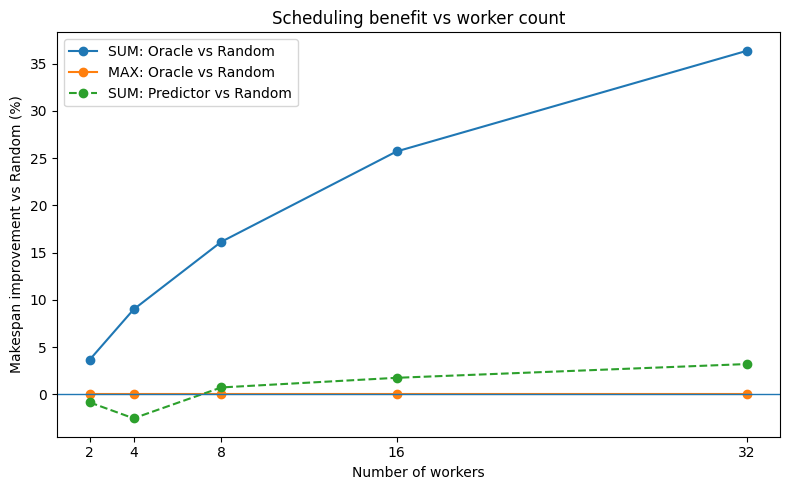

Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_worker_count_sweep.png
✅ M12 deliverable plot frozen.
ℹ️ WAVE curve will be added once observed concurrency is available.


In [35]:
# ============================================================
# WEEK 6 — M12.2
# Worker-count sweep plot
# ============================================================

import matplotlib.pyplot as plt


sum_rows = (
    worker_count_sweep[
        worker_count_sweep["cost_model"] == "sum"
    ]
    .sort_values("n_workers")
)

max_rows = (
    worker_count_sweep[
        worker_count_sweep["cost_model"] == "max"
    ]
    .sort_values("n_workers")
)


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    sum_rows["n_workers"],
    sum_rows["oracle_gain_pct"],
    marker="o",
    label="SUM: Oracle vs Random",
)

plt.plot(
    max_rows["n_workers"],
    max_rows["oracle_gain_pct"],
    marker="o",
    label="MAX: Oracle vs Random",
)

plt.plot(
    sum_rows["n_workers"],
    sum_rows["predicted_gain_pct"],
    marker="o",
    linestyle="--",
    label="SUM: Predictor vs Random",
)

plt.axhline(
    0,
    linewidth=1,
)

plt.xlabel(
    "Number of workers"
)

plt.ylabel(
    "Makespan improvement vs Random (%)"
)

plt.title(
    "Scheduling benefit vs worker count"
)

plt.xticks(
    WORKER_COUNTS
)

plt.legend()

plt.tight_layout()


WORKER_PLOT_PATH = (
    WEEK6_DIR
    / "week6_worker_count_sweep.png"
)

plt.savefig(
    WORKER_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved:",
    WORKER_PLOT_PATH,
)

print(
    "✅ M12 deliverable plot frozen."
)

print(
    "ℹ️ WAVE curve will be added once observed concurrency is available."
)

# M14 — Diagnose the 0.545 → 0.081 Correlation Collapse

The previous-mean response-length estimator transferred poorly:

- controlled uncensored revisit set: Pearson `0.5450`
- independent trace: Pearson `0.080809`

We first decompose independent-trace error into:

1. **batch-level bias / staleness**
2. **within-batch ranking failure**

For each batch, we measure the mean prediction error and Spearman rank
correlation.

We also construct an oracle batch-bias-corrected prediction by subtracting
that batch's mean error. This correction is diagnostic only because it uses
the current batch outcome. Its purpose is to answer:

> If the predictor had the right batch-level offset, would its ranking signal
> become good?

If rank metrics remain weak after removing offset, the collapse cannot be
explained primarily by stale mean bias.

In [36]:
# ============================================================
# WEEK 6 — M14.1
# Bias-versus-rank decomposition on the independent trace
# ============================================================

import numpy as np
import pandas as pd


diagnostic = (
    ablation_cohort[
        [
            "batch_step",
            "predicted_mean_resp_len",
            "true_mean_5",
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# Raw error
#
# Positive error = predictor overestimates true length.
# ------------------------------------------------------------

diagnostic["error"] = (
    diagnostic["predicted_mean_resp_len"]
    - diagnostic["true_mean_5"]
)


# ============================================================
# 1. Batch-level decomposition
# ============================================================

batch_rows = []


for batch_step in range(9, 17):

    b = (
        diagnostic[
            diagnostic["batch_step"]
            == batch_step
        ]
        .copy()
    )

    pred = (
        b["predicted_mean_resp_len"]
        .to_numpy(dtype=float)
    )

    true = (
        b["true_mean_5"]
        .to_numpy(dtype=float)
    )

    error = pred - true

    bias = float(
        error.mean()
    )

    mae = float(
        np.mean(
            np.abs(error)
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                error ** 2
            )
        )
    )

    pearson = (
        pd.Series(pred)
        .corr(
            pd.Series(true),
            method="pearson",
        )
    )

    spearman = (
        pd.Series(pred)
        .corr(
            pd.Series(true),
            method="spearman",
        )
    )

    # --------------------------------------------------------
    # Oracle current-batch bias removal
    #
    # Diagnostic only.
    # --------------------------------------------------------

    corrected_pred = (
        pred
        - bias
    )

    corrected_error = (
        corrected_pred
        - true
    )

    corrected_mae = float(
        np.mean(
            np.abs(
                corrected_error
            )
        )
    )

    corrected_rmse = float(
        np.sqrt(
            np.mean(
                corrected_error ** 2
            )
        )
    )

    corrected_pearson = (
        pd.Series(
            corrected_pred
        )
        .corr(
            pd.Series(true),
            method="pearson",
        )
    )

    corrected_spearman = (
        pd.Series(
            corrected_pred
        )
        .corr(
            pd.Series(true),
            method="spearman",
        )
    )

    batch_rows.append(
        {
            "batch_step":
                batch_step,

            "n":
                len(b),

            "predicted_mean":
                float(
                    pred.mean()
                ),

            "true_mean":
                float(
                    true.mean()
                ),

            "mean_bias_pred_minus_true":
                bias,

            "mae":
                mae,

            "rmse":
                rmse,

            "pearson":
                pearson,

            "spearman":
                spearman,

            "oracle_bias_corrected_mae":
                corrected_mae,

            "oracle_bias_corrected_rmse":
                corrected_rmse,

            "oracle_bias_corrected_pearson":
                corrected_pearson,

            "oracle_bias_corrected_spearman":
                corrected_spearman,
        }
    )


bias_rank_by_batch = pd.DataFrame(
    batch_rows
)


# ============================================================
# 2. Exact MSE decomposition
#
# error_i = batch_bias_b + centered_error_i
#
# SSE_total =
#     SSE_batch_bias
#   + SSE_within_batch_residual
# ============================================================

total_sse = float(
    np.sum(
        diagnostic["error"]
        .to_numpy(dtype=float) ** 2
    )
)

bias_sse = 0.0
within_sse = 0.0


for batch_step in range(9, 17):

    b = (
        diagnostic[
            diagnostic["batch_step"]
            == batch_step
        ]
        .copy()
    )

    errors = (
        b["error"]
        .to_numpy(dtype=float)
    )

    batch_bias = float(
        errors.mean()
    )

    bias_sse += (
        len(errors)
        * batch_bias ** 2
    )

    centered = (
        errors
        - batch_bias
    )

    within_sse += float(
        np.sum(
            centered ** 2
        )
    )


assert np.isclose(
    total_sse,
    bias_sse + within_sse,
)


bias_fraction_mse = (
    bias_sse
    / total_sse
)

within_fraction_mse = (
    within_sse
    / total_sse
)


# ============================================================
# 3. Global oracle batch-bias correction
# ============================================================

diagnostic = diagnostic.merge(
    bias_rank_by_batch[
        [
            "batch_step",
            "mean_bias_pred_minus_true",
        ]
    ],
    on="batch_step",
    how="left",
    validate="many_to_one",
)


diagnostic[
    "oracle_batch_bias_corrected_pred"
] = (
    diagnostic[
        "predicted_mean_resp_len"
    ]
    - diagnostic[
        "mean_bias_pred_minus_true"
    ]
)


raw_global_pearson = (
    diagnostic[
        "predicted_mean_resp_len"
    ]
    .corr(
        diagnostic[
            "true_mean_5"
        ],
        method="pearson",
    )
)

raw_global_spearman = (
    diagnostic[
        "predicted_mean_resp_len"
    ]
    .corr(
        diagnostic[
            "true_mean_5"
        ],
        method="spearman",
    )
)


corrected_global_pearson = (
    diagnostic[
        "oracle_batch_bias_corrected_pred"
    ]
    .corr(
        diagnostic[
            "true_mean_5"
        ],
        method="pearson",
    )
)

corrected_global_spearman = (
    diagnostic[
        "oracle_batch_bias_corrected_pred"
    ]
    .corr(
        diagnostic[
            "true_mean_5"
        ],
        method="spearman",
    )
)


raw_mae = float(
    np.mean(
        np.abs(
            diagnostic["error"]
        )
    )
)

corrected_mae = float(
    np.mean(
        np.abs(
            diagnostic[
                "oracle_batch_bias_corrected_pred"
            ]
            - diagnostic[
                "true_mean_5"
            ]
        )
    )
)


# ============================================================
# Display
# ============================================================

print("=" * 125)
print(
    "M14.1 — BIAS-VERSUS-RANK DECOMPOSITION"
)
print("=" * 125)

display_cols = [
    "batch_step",
    "predicted_mean",
    "true_mean",
    "mean_bias_pred_minus_true",
    "mae",
    "spearman",
    "oracle_bias_corrected_mae",
    "oracle_bias_corrected_spearman",
]

print(
    bias_rank_by_batch[
        display_cols
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}",
    )
)


print("\n" + "=" * 80)
print("ERROR DECOMPOSITION")
print("=" * 80)

print(
    f"Total squared error       : "
    f"{total_sse:,.2f}"
)

print(
    f"Batch-bias component      : "
    f"{bias_sse:,.2f} "
    f"({bias_fraction_mse * 100:.2f}%)"
)

print(
    f"Within-batch residual     : "
    f"{within_sse:,.2f} "
    f"({within_fraction_mse * 100:.2f}%)"
)


print("\n" + "=" * 80)
print("GLOBAL METRICS")
print("=" * 80)

print("Raw predictor:")
print(
    f"Pearson  = "
    f"{raw_global_pearson:.6f}"
)
print(
    f"Spearman = "
    f"{raw_global_spearman:.6f}"
)
print(
    f"MAE      = "
    f"{raw_mae:.3f}"
)

print("\nOracle batch-bias corrected:")
print(
    f"Pearson  = "
    f"{corrected_global_pearson:.6f}"
)
print(
    f"Spearman = "
    f"{corrected_global_spearman:.6f}"
)
print(
    f"MAE      = "
    f"{corrected_mae:.3f}"
)


# ============================================================
# Freeze artifact
# ============================================================

BIAS_RANK_PATH = (
    WEEK6_DIR
    / "week6_bias_rank_decomposition.csv"
)

bias_rank_by_batch.to_csv(
    BIAS_RANK_PATH,
    index=False,
)

print(
    "\nSaved:",
    BIAS_RANK_PATH,
)

print(
    "\n✅ M14.1 bias-versus-rank decomposition complete."
)

M14.1 — BIAS-VERSUS-RANK DECOMPOSITION
 batch_step  predicted_mean  true_mean  mean_bias_pred_minus_true     mae  spearman  oracle_bias_corrected_mae  oracle_bias_corrected_spearman
          9         897.605    884.973                     12.631 507.569    -0.015                    507.371                          -0.015
         10         872.455    790.458                     81.997 440.353     0.197                    441.159                           0.197
         11         845.430    807.267                     38.163 475.900    -0.004                    479.293                          -0.004
         12         842.036    697.834                    144.202 385.027     0.212                    378.680                           0.212
         13         807.328    687.809                    119.519 365.125     0.263                    350.194                           0.263
         14         852.045    649.295                    202.750 461.194    -0.002                    

# M15 — EWMA Bias Correction on the Independent Trace

The oracle batch-bias diagnostic showed that batch-level offset explains only
a small fraction of the prediction error.

We now test the actual leakage-safe Week 4 correction:

`corrected_prediction = previous_mean_prediction + EWMA_bias`

with:

- `alpha = 0.10`
- initial bias = `0`
- prediction made before observing the current batch
- EWMA updated only after the current batch outcomes are available

The EWMA tracks:

`actual_mean_length - raw_previous_mean_prediction`

This correction can improve calibration across batches, but because it adds
the same offset to every prediction inside a batch, it cannot improve
within-batch rank correlation.

In [38]:
# ============================================================
# WEEK 6 — M15.1
# Leakage-safe EWMA bias correction
# ============================================================

import numpy as np
import pandas as pd


EWMA_ALPHA = 0.10

ewma_bias = 0.0

ewma_rows = []
ewma_state_rows = []


for batch_step in range(9, 17):

    batch = (
        ablation_cohort[
            ablation_cohort["batch_step"]
            == batch_step
        ]
        .copy()
        .reset_index(drop=True)
    )

    raw_pred = (
        batch["predicted_mean_resp_len"]
        .to_numpy(dtype=float)
    )

    true = (
        batch["true_mean_5"]
        .to_numpy(dtype=float)
    )

    # --------------------------------------------------------
    # Predict using ONLY state from completed earlier batches.
    # --------------------------------------------------------

    bias_used = float(
        ewma_bias
    )

    corrected_pred = (
        raw_pred
        + bias_used
    )

    # --------------------------------------------------------
    # Record predictions before updating EWMA state.
    # --------------------------------------------------------

    for i in range(len(batch)):

        ewma_rows.append(
            {
                "batch_step":
                    batch_step,

                "occurrence_id":
                    batch.loc[
                        i,
                        "occurrence_id",
                    ],

                "example_key":
                    batch.loc[
                        i,
                        "example_key",
                    ],

                "raw_prediction":
                    raw_pred[i],

                "ewma_bias_used":
                    bias_used,

                "ewma_prediction":
                    corrected_pred[i],

                "true_mean_5":
                    true[i],

                "rollout_lengths":
                    batch.loc[
                        i,
                        "rollout_lengths",
                    ],
            }
        )

    # --------------------------------------------------------
    # Observe current batch.
    #
    # Week 4 EWMA tracks:
    #
    # actual - baseline_prediction
    #
    # Positive residual:
    # baseline predicts too short.
    #
    # Negative residual:
    # baseline predicts too long.
    # --------------------------------------------------------

    observed_batch_bias = float(
        np.mean(
            true
            - raw_pred
        )
    )

    ewma_before_update = float(
        ewma_bias
    )

    ewma_bias = (
        (1.0 - EWMA_ALPHA)
        * ewma_bias
        + EWMA_ALPHA
        * observed_batch_bias
    )

    ewma_state_rows.append(
        {
            "batch_step":
                batch_step,

            "ewma_bias_used":
                ewma_before_update,

            "observed_actual_minus_raw":
                observed_batch_bias,

            "ewma_bias_after_update":
                ewma_bias,
        }
    )


ewma_cohort = pd.DataFrame(
    ewma_rows
)

ewma_state = pd.DataFrame(
    ewma_state_rows
)


# ============================================================
# Global metrics
# ============================================================

raw_pearson = (
    ewma_cohort[
        "raw_prediction"
    ]
    .corr(
        ewma_cohort[
            "true_mean_5"
        ],
        method="pearson",
    )
)

raw_spearman = (
    ewma_cohort[
        "raw_prediction"
    ]
    .corr(
        ewma_cohort[
            "true_mean_5"
        ],
        method="spearman",
    )
)

raw_mae = float(
    np.mean(
        np.abs(
            ewma_cohort[
                "raw_prediction"
            ]
            - ewma_cohort[
                "true_mean_5"
            ]
        )
    )
)


ewma_pearson = (
    ewma_cohort[
        "ewma_prediction"
    ]
    .corr(
        ewma_cohort[
            "true_mean_5"
        ],
        method="pearson",
    )
)

ewma_spearman = (
    ewma_cohort[
        "ewma_prediction"
    ]
    .corr(
        ewma_cohort[
            "true_mean_5"
        ],
        method="spearman",
    )
)

ewma_mae = float(
    np.mean(
        np.abs(
            ewma_cohort[
                "ewma_prediction"
            ]
            - ewma_cohort[
                "true_mean_5"
            ]
        )
    )
)


# ============================================================
# Within-batch rank metrics
# ============================================================

rank_rows = []


for batch_step in range(9, 17):

    b = (
        ewma_cohort[
            ewma_cohort[
                "batch_step"
            ] == batch_step
        ]
        .copy()
    )

    raw_batch_spearman = (
        b["raw_prediction"]
        .corr(
            b["true_mean_5"],
            method="spearman",
        )
    )

    ewma_batch_spearman = (
        b["ewma_prediction"]
        .corr(
            b["true_mean_5"],
            method="spearman",
        )
    )

    rank_rows.append(
        {
            "batch_step":
                batch_step,

            "raw_spearman":
                raw_batch_spearman,

            "ewma_spearman":
                ewma_batch_spearman,

            "difference":
                (
                    ewma_batch_spearman
                    - raw_batch_spearman
                ),
        }
    )


ewma_rank_by_batch = pd.DataFrame(
    rank_rows
)


# Uniform within-batch offsets must preserve rank exactly.
assert np.allclose(
    ewma_rank_by_batch[
        "raw_spearman"
    ],
    ewma_rank_by_batch[
        "ewma_spearman"
    ],
    equal_nan=True,
)


# ============================================================
# Display
# ============================================================

print("=" * 95)
print("M15.1 — EWMA BIAS STATE")
print("=" * 95)

print(
    ewma_state.to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}",
    )
)


print("\n" + "=" * 95)
print("RAW VS EWMA-CORRECTED PREDICTOR")
print("=" * 95)

print("Raw previous-mean predictor:")
print(
    f"Pearson  = {raw_pearson:.6f}"
)
print(
    f"Spearman = {raw_spearman:.6f}"
)
print(
    f"MAE      = {raw_mae:.3f}"
)

print("\nEWMA-corrected predictor:")
print(
    f"Pearson  = {ewma_pearson:.6f}"
)
print(
    f"Spearman = {ewma_spearman:.6f}"
)
print(
    f"MAE      = {ewma_mae:.3f}"
)


print("\n" + "=" * 95)
print("WITHIN-BATCH SPEARMAN")
print("=" * 95)

print(
    ewma_rank_by_batch.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(
    "\nMean raw batch Spearman : "
    f"{ewma_rank_by_batch['raw_spearman'].mean():.6f}"
)

print(
    "Mean EWMA batch Spearman: "
    f"{ewma_rank_by_batch['ewma_spearman'].mean():.6f}"
)


# ============================================================
# Freeze artifacts
# ============================================================

EWMA_PRED_PATH = (
    WEEK6_DIR
    / "week6_ewma_corrected_predictions.csv"
)

EWMA_STATE_PATH = (
    WEEK6_DIR
    / "week6_ewma_bias_state.csv"
)

ewma_cohort.drop(
    columns=["rollout_lengths"]
).to_csv(
    EWMA_PRED_PATH,
    index=False,
)

ewma_state.to_csv(
    EWMA_STATE_PATH,
    index=False,
)


print(
    "\nSaved:",
    EWMA_PRED_PATH,
)

print(
    "Saved:",
    EWMA_STATE_PATH,
)

print(
    "\n✅ M15.1 leakage-safe EWMA correction complete."
)

M15.1 — EWMA BIAS STATE
 batch_step  ewma_bias_used  observed_actual_minus_raw  ewma_bias_after_update
          9           0.000                    -12.631                  -1.263
         10          -1.263                    -81.997                  -9.337
         11          -9.337                    -38.163                 -12.219
         12         -12.219                   -144.202                 -25.417
         13         -25.417                   -119.519                 -34.827
         14         -34.827                   -202.750                 -51.620
         15         -51.620                    -20.259                 -48.484
         16         -48.484                   -110.525                 -54.688

RAW VS EWMA-CORRECTED PREDICTOR
Raw previous-mean predictor:
Pearson  = 0.080809
Spearman = 0.117513
MAE      = 438.365

EWMA-corrected predictor:
Pearson  = 0.084635
Spearman = 0.120642
MAE      = 435.538

WITHIN-BATCH SPEARMAN
 batch_step  raw_spearman  ewma_spe

## M15.2 — Regime Comparison

The controlled Week 5 length result and the independent-trace result come
from materially different evaluation regimes.

The controlled dataset was strongly censored near 1,024 tokens, and the
headline Pearson correlation of 0.545 was measured only on 39 fully
uncensored held-out occurrences.

The independent trace contains a much broader response-length distribution
and evaluates 1,024 second-epoch prompt occurrences.

This comparison tests whether the apparent transfer collapse is partly a
distribution/regime shift rather than only predictor staleness.

In [39]:
# ============================================================
# WEEK 6 — M15.2
# Controlled-vs-independent regime comparison
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Frozen Week 5 controlled-trace statistics
#
# These come from the completed Week 5 analysis.
# ------------------------------------------------------------

CONTROLLED_MEAN = 547.897
CONTROLLED_STD = 352.520
CONTROLLED_MAX = 1130.0
CONTROLLED_GE_1024_PCT = 20.938

CONTROLLED_HEADLINE_PEARSON = 0.5450
CONTROLLED_HEADLINE_SPEARMAN = 0.4354
CONTROLLED_HEADLINE_MAE = 145.59
CONTROLLED_HEADLINE_N = 39


# ------------------------------------------------------------
# Independent trace statistics
# ------------------------------------------------------------

independent_lengths = (
    trace_rollouts["resp_len"]
    .to_numpy(dtype=float)
)

independent_mean = float(
    independent_lengths.mean()
)

independent_std = float(
    independent_lengths.std(ddof=1)
)

independent_max = float(
    independent_lengths.max()
)

independent_ge_1024_pct = float(
    np.mean(
        independent_lengths >= 1024
    )
    * 100
)

independent_median = float(
    np.median(
        independent_lengths
    )
)

independent_p90 = float(
    np.percentile(
        independent_lengths,
        90,
    )
)

independent_p95 = float(
    np.percentile(
        independent_lengths,
        95,
    )
)

independent_p99 = float(
    np.percentile(
        independent_lengths,
        99,
    )
)


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

regime_comparison = pd.DataFrame(
    [
        {
            "regime":
                "Week 5 controlled",

            "rollout_mean":
                CONTROLLED_MEAN,

            "rollout_std":
                CONTROLLED_STD,

            "rollout_max":
                CONTROLLED_MAX,

            "pct_ge_1024":
                CONTROLLED_GE_1024_PCT,

            "headline_eval_n":
                CONTROLLED_HEADLINE_N,

            "headline_pearson":
                CONTROLLED_HEADLINE_PEARSON,

            "headline_spearman":
                CONTROLLED_HEADLINE_SPEARMAN,

            "headline_mae":
                CONTROLLED_HEADLINE_MAE,
        },

        {
            "regime":
                "Independent trace",

            "rollout_mean":
                independent_mean,

            "rollout_std":
                independent_std,

            "rollout_max":
                independent_max,

            "pct_ge_1024":
                independent_ge_1024_pct,

            "headline_eval_n":
                len(ablation_cohort),

            "headline_pearson":
                raw_pearson,

            "headline_spearman":
                raw_spearman,

            "headline_mae":
                raw_mae,
        },
    ]
)


# ------------------------------------------------------------
# Distribution-shift ratios
# ------------------------------------------------------------

mean_ratio = (
    independent_mean
    / CONTROLLED_MEAN
)

max_ratio = (
    independent_max
    / CONTROLLED_MAX
)


print("=" * 105)
print("M15.2 — CONTROLLED VS INDEPENDENT REGIME")
print("=" * 105)

print(
    regime_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:,.3f}",
    )
)


print("\nIndependent trace tail:")
print(
    f"Median = {independent_median:,.1f}"
)
print(
    f"P90    = {independent_p90:,.1f}"
)
print(
    f"P95    = {independent_p95:,.1f}"
)
print(
    f"P99    = {independent_p99:,.1f}"
)


print("\nDistribution shift:")

print(
    f"Independent mean / controlled mean "
    f"= {mean_ratio:.3f}x"
)

print(
    f"Independent max / controlled max "
    f"= {max_ratio:.3f}x"
)


# ------------------------------------------------------------
# Freeze artifact
# ------------------------------------------------------------

REGIME_PATH = (
    WEEK6_DIR
    / "week6_length_regime_comparison.csv"
)

regime_comparison.to_csv(
    REGIME_PATH,
    index=False,
)


print(
    "\nSaved:",
    REGIME_PATH,
)

print(
    "\n✅ M15.2 regime comparison complete."
)

M15.2 — CONTROLLED VS INDEPENDENT REGIME
           regime  rollout_mean  rollout_std  rollout_max  pct_ge_1024  headline_eval_n  headline_pearson  headline_spearman  headline_mae
Week 5 controlled       547.897      352.520    1,130.000       20.938               39             0.545              0.435       145.590
Independent trace       815.922      897.291    5,563.000       23.389             1024             0.081              0.118       438.365

Independent trace tail:
Median = 418.0
P90    = 2,656.0
P95    = 3,072.0
P99    = 3,074.0

Distribution shift:
Independent mean / controlled mean = 1.489x
Independent max / controlled max = 4.923x

Saved: C:\Users\waqar\OneDrive\Desktop\Fellowship\week_6\week6_length_regime_comparison.csv

✅ M15.2 regime comparison complete.


## Objective 5 Conclusion

The controlled-to-independent correlation collapse is not primarily explained
by a stale batch-level offset.

On the independent trace:

- batch-level bias explains only 3.78% of total squared prediction error,
- 96.22% remains as within-batch residual error,
- oracle batch-bias correction raises Pearson only from 0.0808 to 0.1041,
- leakage-safe EWMA raises Pearson only to 0.0846,
- EWMA reduces MAE from 438.37 to 435.54,
- mean within-batch Spearman remains exactly 0.112878.

The evaluation regimes also differ substantially:

- controlled rollout mean: 547.9 tokens
- independent rollout mean: 815.9 tokens
- controlled maximum: 1,130
- independent maximum: 5,563
- independent standard deviation: 897.3 tokens

The earlier Pearson 0.545 result was additionally measured on only 39 fully
uncensored held-out occurrences, while the independent evaluation uses 1,024
second-epoch occurrences.

Therefore the observed 0.545 → 0.081 collapse is best attributed to a
combination of distribution/regime mismatch and genuine failure of the
previous-length signal to preserve within-batch ranking on the independent
trace.

EWMA corrects a small amount of calibration drift but does not recover the
ranking signal required by the scheduler.

Because the collapse is not mostly bias, the conditional EWMA scheduling
re-run is not warranted.

Objective 1  Cost models                  ✅
             SUM / MAX / WAVE sweep       ✅
             real observed WAVE C         ⏳ Sam

Objective 2  Within-batch bubble          ✅
             Oracle + predicted + C sweep ✅

Objective 3  Rank-based benefit curve     ✅
             Gaussian + rank corruption   ✅
             refined 90% thresholds       ✅

Objective 4  Worker-count sweep           ✅ SUM/MAX
             WAVE worker sweep            ⏳ Sam's C

Objective 5  Correlation-collapse cause   ✅
             EWMA test                    ✅
             regime comparison            ✅
             corrected scheduler rerun    SKIPPED, not warranted